# **SYSTEM CHECK & IMPORTS**

In [3]:
import os
import json
import sys
import re
import random
import warnings
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import monai
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from pathlib import Path
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from skimage.transform import resize as sk_resize
from tqdm import tqdm

warnings.filterwarnings("ignore")

print(f"Python     : {sys.executable}")
print(f"PyTorch    : {torch.__version__}")
print(f"MONAI      : {monai.__version__}")
print(f"GPU        : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device : {torch.cuda.get_device_name(0)}")
    print(f"VRAM       : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device     : {device}")

Python     : C:\Users\Omar\miniconda3\envs\liver_mri\python.exe
PyTorch    : 2.5.1+cu121
MONAI      : 1.5.2
GPU        : True
GPU Device : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM       : 6.44 GB
Device     : cuda


# **Data Loading & Preprocessing**

In [4]:
DATA_DIR   = Path(r"E:\TAAA7\Graduation project\MRI\New_MRI (3D)\data")
JSON_PATH = r"E:\TAAA7\Graduation project\MRI\New_MRI (3D)\data\LLD_MMRI_Annotation.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    a = json.load(f)

if "Category_info" in a:
    print(json.dumps(a["Category_info"], indent=2))
else:
    print(a.keys())

{
  "Hepatic_hemangioma": 0,
  "Intrahepatic_cholangiocarcinoma": 1,
  "Hepatic_abscess": 2,
  "Hepatic_metastasis": 3,
  "Hepatic_cyst": 4,
  "FOCAL_NODULAR_HYPERPLASIA": 5,
  "Hepatocellular_carcinoma": 6,
  "Benign": [
    0,
    2,
    4,
    5
  ],
  "Malignant": [
    1,
    3,
    6
  ]
}


In [5]:
DATA_DIR   = Path(r"E:\TAAA7\Graduation project\MRI\New_MRI (3D)\data")
IMAGES_DIR = DATA_DIR / "images"
LABELS_DIR = DATA_DIR / "labels"
JSON_PATH  = DATA_DIR / "LLD_MMRI_Annotation.json"

TARGET_SHAPE = (32, 96, 96)
NUM_CLASSES  = 7
BATCH_SIZE   = 2
NUM_EPOCHS   = 60
LR           = 1e-4
PATIENCE     = 15

BASE_PATH = r"E:\TAAA7\Graduation project\MRI\New_MRI (3D)\connection_MRI"
SEG_MODEL1_PATH  = BASE_PATH + r"\best_seg_model1_DWI.pth"
SEG_MODEL2_PATH  = BASE_PATH + r"\best_seg_model2_T2WI.pth"
SEG_MODEL3_PATH  = BASE_PATH + r"\best_seg_model3_cascade.pth"
CLS_MODEL1_PATH  = BASE_PATH + r"\best_cls_model1_malignant.pth"
CLS_MODEL2_PATH  = BASE_PATH + r"\best_cls_model2_malignant_type.pth"
CLS_MODEL3_PATH  = BASE_PATH + r"\best_cls_model3_benign_type.pth"

SCAN_TYPES = ["C-pre", "C+A", "C+V", "C+Delay", "T2WI", "DWI", "In Phase", "Out Phase"]

PHASE_FILE_MAP = {
    "C-pre": "C-pre", "C+A": "C+A", "C+V": "C+V", "C+Delay": "C+Delay",
    "T2WI": "T2WI", "DWI": "DWI", "In Phase": "InPhase", "Out Phase": "OutPhase"
}

CATEGORY_MAP = {
    0: "Hepatic Hemangioma",
    1: "Intrahepatic Cholangiocarcinoma",
    2: "Hepatic Abscess",
    3: "Hepatic Metastasis",
    4: "Hepatic Cyst",
    5: "Focal Nodular Hyperplasia",
    6: "Hepatocellular Carcinoma"
}

MALIGNANT = [1, 3, 6]
BENIGN    = [0, 2, 4, 5]

# Malignant sub-classes
MALIGNANT_MAP  = {1: 0, 3: 1, 6: 2}  # ICC=0, Metastasis=1, HCC=2
MALIGNANT_NAME = {0: "Intrahepatic Cholangiocarcinoma", 1: "Hepatic Metastasis", 2: "Hepatocellular Carcinoma"}

# Benign sub-classes
BENIGN_MAP  = {0: 0, 2: 1, 4: 2, 5: 3}  # Hemangioma=0, Abscess=1, Cyst=2, FNH=3
BENIGN_NAME = {0: "Hepatic Hemangioma", 1: "Hepatic Abscess", 2: "Hepatic Cyst", 3: "Focal Nodular Hyperplasia"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f" Config done! Device: {device}")
print(f"   Images : {len(list(IMAGES_DIR.glob('*.nii.gz')))}")
print(f"   Labels : {len(list(LABELS_DIR.glob('*.nii.gz')))}")
print(f"   JSON   : {JSON_PATH.exists()}")

 Config done! Device: cuda
   Images : 3928
   Labels : 3984
   JSON   : True


In [6]:
def parse_annotations(json_path):
    with open(json_path) as f:
        data = json.load(f)
    patient_data = defaultdict(dict)
    for pid, scans in data["Annotation_info"].items():
        for scan in scans:
            if scan["annotation"]["num_targets"] == 0:
                continue
            category = scan["annotation"]["lesion"]["0"]["category"]
            patient_data[pid][scan["phase"]] = {
                "category":     category,
                "is_malignant": int(category in MALIGNANT),
                "disease_name": CATEGORY_MAP[category]
            }
    return patient_data

patient_data = parse_annotations(JSON_PATH)

complete_patients = {
    pid: scans for pid, scans in patient_data.items()
    if all(p in scans for p in SCAN_TYPES)
}
print(f" Total patients        : {len(patient_data)}")
print(f" Complete patients (8) : {len(complete_patients)}")

 Total patients        : 498
 Complete patients (8) : 498


In [7]:
patient_ids = list(complete_patients.keys())
train_ids, test_ids = train_test_split(patient_ids, test_size=0.15, random_state=42)
train_ids, val_ids  = train_test_split(train_ids,   test_size=0.15, random_state=42)

print(f" Train : {len(train_ids)}")
print(f" Val   : {len(val_ids)}")
print(f" Test  : {len(test_ids)}")

labels = [complete_patients[pid][SCAN_TYPES[0]]["category"] for pid in train_ids]
print(f"\n Train Class Distribution:")
for cls_id, count in sorted(Counter(labels).items()):
    print(f"   {CATEGORY_MAP[cls_id]:<40}: {count}")

 Train : 359
 Val   : 64
 Test  : 75

 Train Class Distribution:
   Hepatic Hemangioma                      : 63
   Intrahepatic Cholangiocarcinoma         : 38
   Hepatic Abscess                         : 41
   Hepatic Metastasis                      : 32
   Hepatic Cyst                            : 39
   Focal Nodular Hyperplasia               : 32
   Hepatocellular Carcinoma                : 114


In [8]:
def normalize(vol):
    """Z-score normalization"""
    mean = vol.mean()
    std  = vol.std()
    if std > 0:
        return (vol - mean) / std
    return vol - mean

def resize_volume(vol, target_shape):
    """ images"""
    t = torch.tensor(vol).unsqueeze(0).unsqueeze(0)
    r = F.interpolate(t, size=target_shape, mode="trilinear", align_corners=False)
    return r.squeeze().numpy()

def resize_mask(mask, target_shape):
    t = torch.tensor(mask).unsqueeze(0).unsqueeze(0)
    r = F.interpolate(t, size=target_shape, mode="nearest")
    return r.squeeze().numpy()

def load_nifti(path):
    return nib.load(str(path)).get_fdata().astype(np.float32)

def find_file(directory, pid, phase):
    fname = PHASE_FILE_MAP.get(phase, phase)
    files = list(Path(directory).glob(f"{pid}*{fname}*.nii.gz"))
    return files[0] if files else None

print(" Helper functions ready!")

 Helper functions ready!


# **Visualization**

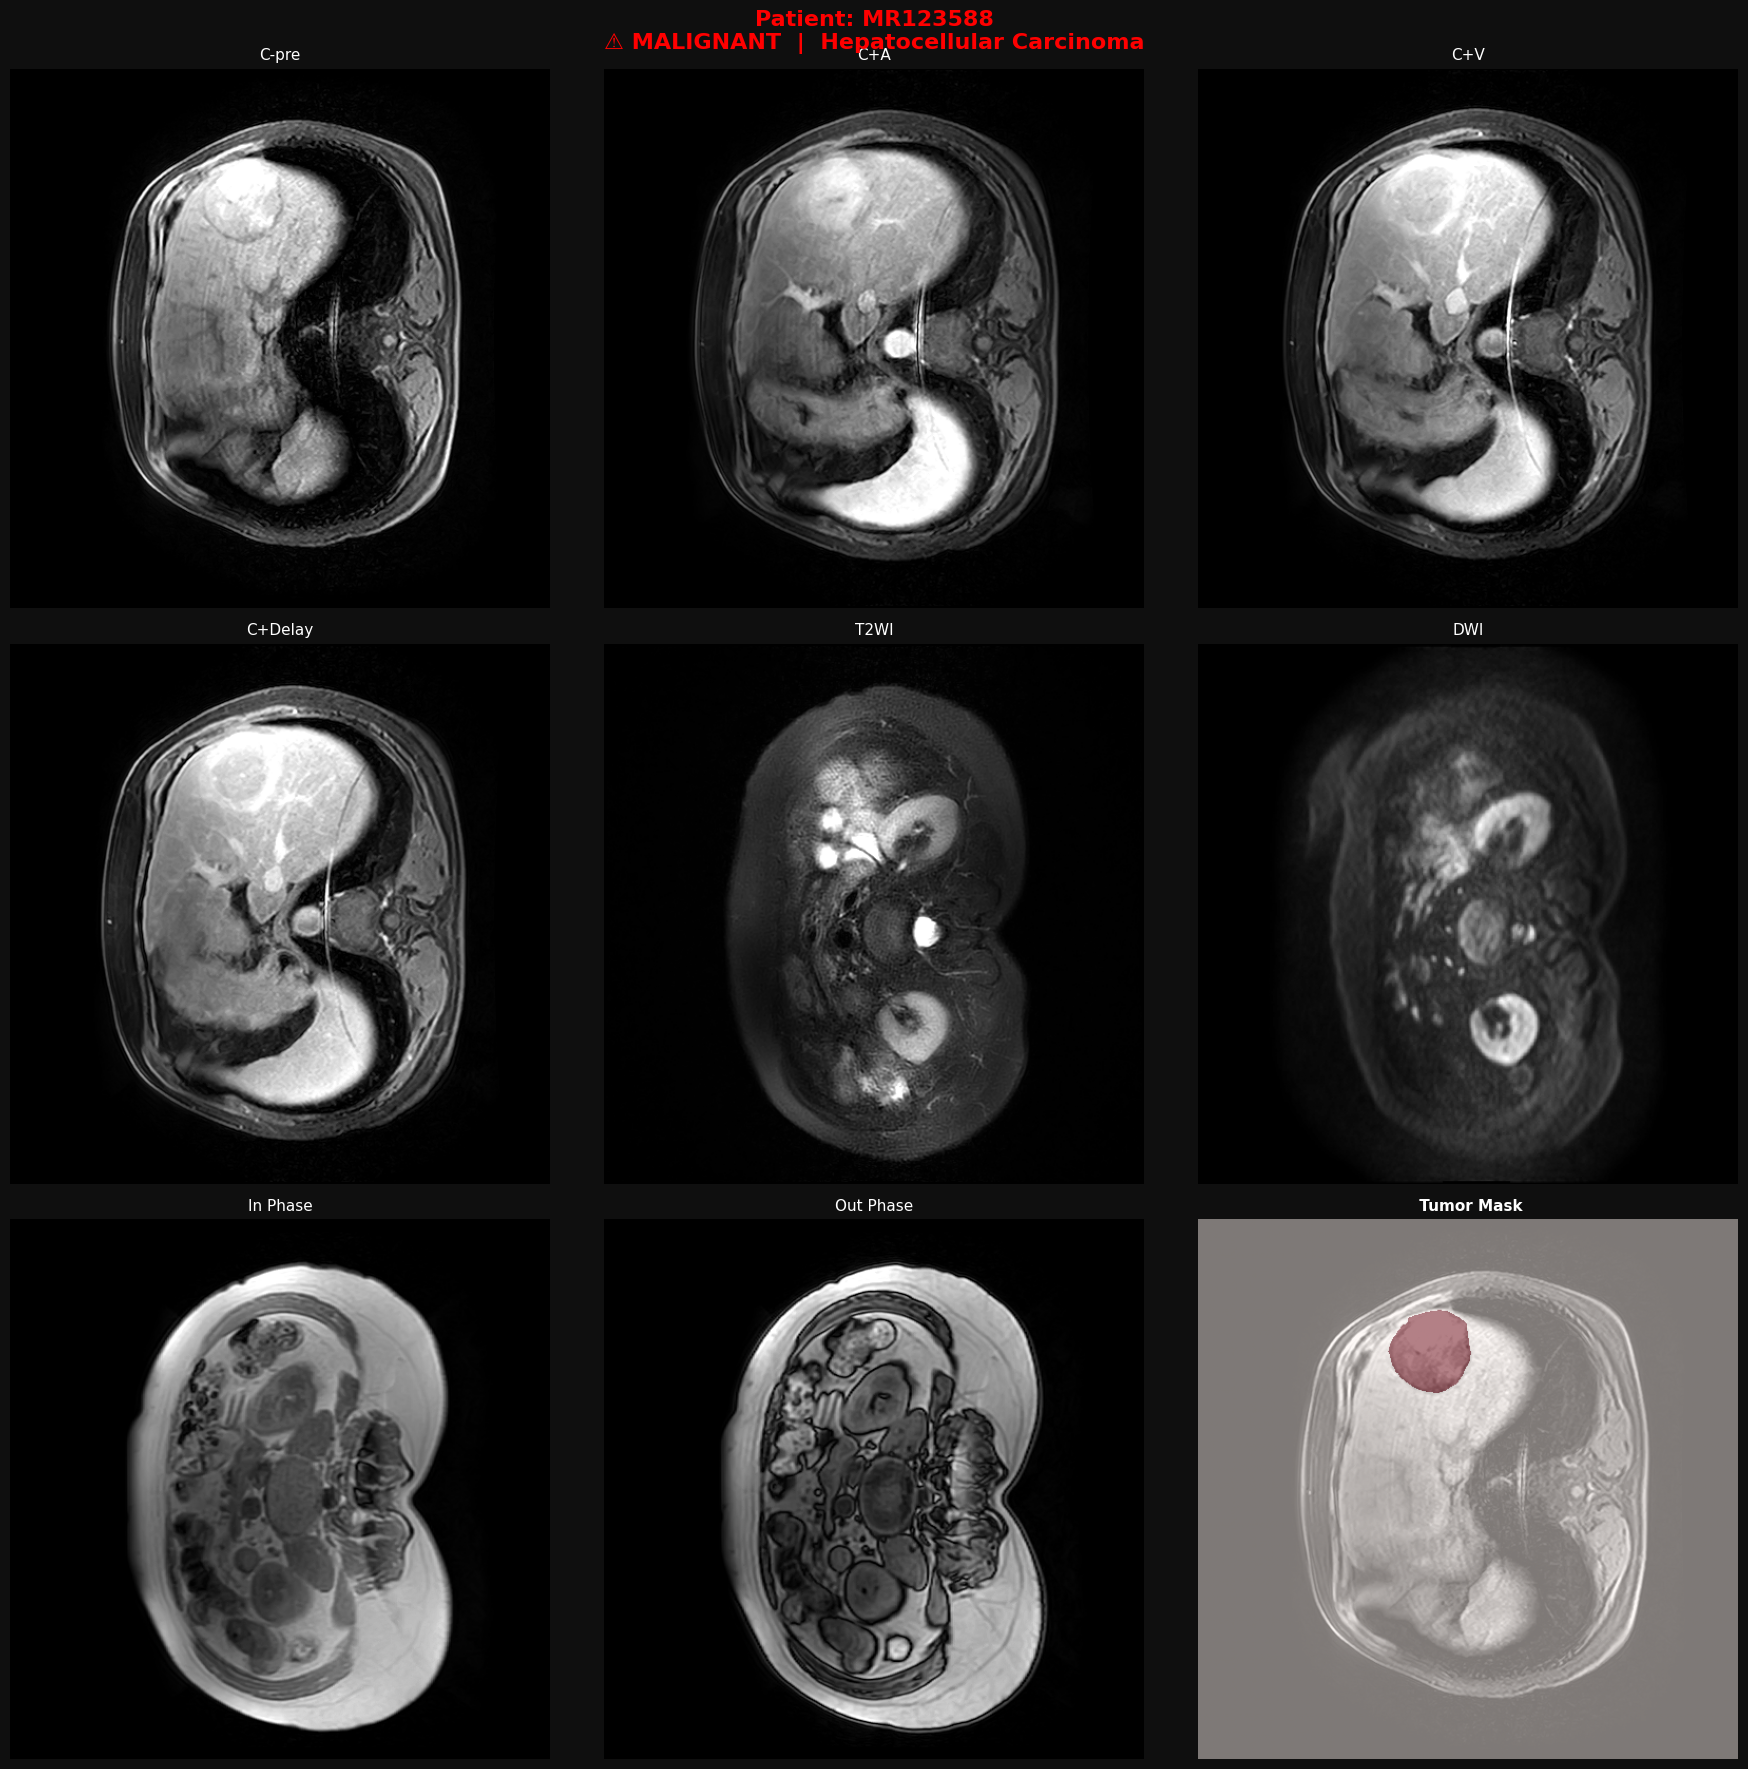

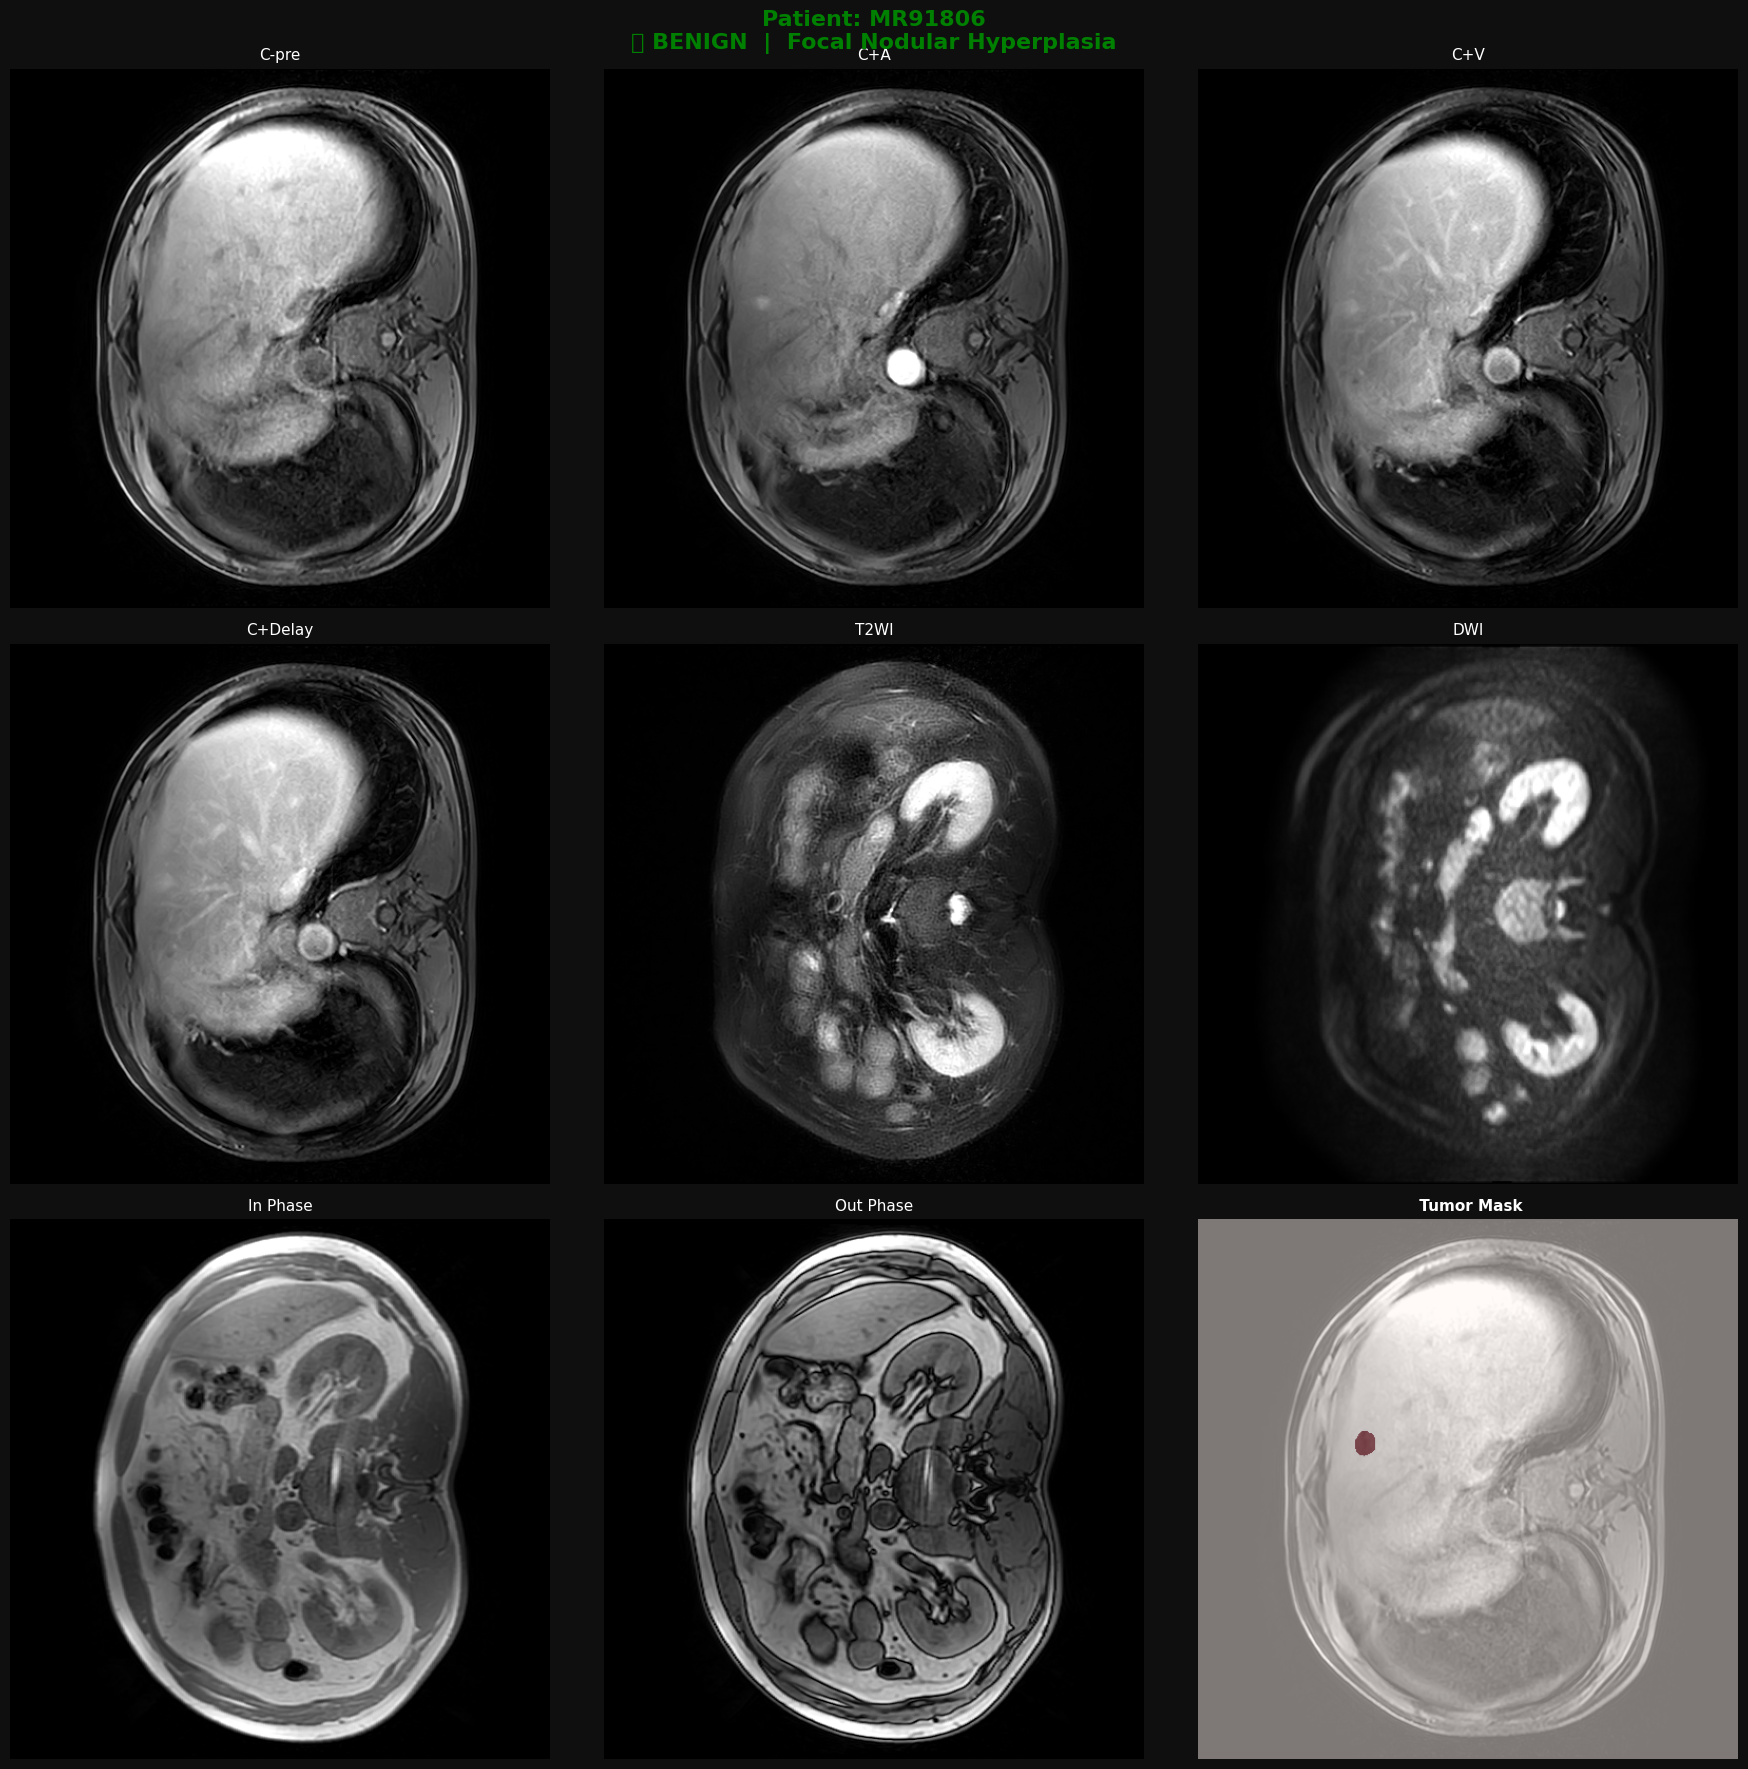

In [10]:
def visualize_patient(pid):
    info    = complete_patients[pid][SCAN_TYPES[0]]
    disease = info["disease_name"]
    is_mal  = info["is_malignant"]
    status  = "⚠️ MALIGNANT" if is_mal else "✅ BENIGN"
    color   = "red" if is_mal else "green"

    mask_path = find_file(LABELS_DIR, pid, SCAN_TYPES[0])
    mask      = load_nifti(mask_path) if mask_path else None
    best_sl   = int(np.argmax([mask[:,:,i].sum() for i in range(mask.shape[2])])) \
                if mask is not None else 0

    fig, axes = plt.subplots(3, 3, figsize=(18, 18))
    fig.patch.set_facecolor("#0f0f0f")
    fig.suptitle(f"Patient: {pid}\n{status}  |  {disease}",
                 fontsize=16, color=color, fontweight="bold")
    axes = axes.flatten()

    for i, phase in enumerate(SCAN_TYPES):
        path = find_file(IMAGES_DIR, pid, phase)
        if path:
            vol = load_nifti(path)
            sl  = min(best_sl, vol.shape[2]-1)
            axes[i].imshow(vol[:,:,sl], cmap="gray")
        axes[i].set_title(phase, color="white", fontsize=11)
        axes[i].set_facecolor("black")
        axes[i].axis("off")

    img_path = find_file(IMAGES_DIR, pid, SCAN_TYPES[0])
    if img_path and mask is not None:
        vol          = load_nifti(img_path)
        sl           = min(best_sl, vol.shape[2]-1)
        mask_resized = sk_resize(mask[:,:,best_sl], vol[:,:,sl].shape,
                                 order=0, preserve_range=True)
        axes[8].imshow(vol[:,:,sl], cmap="gray")
        axes[8].imshow(mask_resized, cmap="Reds", alpha=0.5)
    axes[8].set_title(" Tumor Mask", color="white", fontsize=11, fontweight="bold")
    axes[8].set_facecolor("black")
    axes[8].axis("off")

    plt.tight_layout()
    plt.show()

for pid in train_ids[:2]:
    visualize_patient(pid)

# **Dataset**

In [9]:
class DWIDataset(Dataset):
    def __init__(self, patient_ids, patient_data, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid = self.patient_ids[idx]

        # DWI بس
        path = find_file(IMAGES_DIR, pid, "DWI")
        if path:
            vol = load_nifti(path)
            vol = normalize(vol)
            vol = resize_volume(vol, TARGET_SHAPE)
        else:
            vol = np.zeros(TARGET_SHAPE, dtype=np.float32)

        image = torch.tensor(vol, dtype=torch.float32).unsqueeze(0)  # (1, D, H, W)

        # Mask
        mask = np.zeros(TARGET_SHAPE, dtype=np.float32)
        path = find_file(LABELS_DIR, pid, "DWI")
        if path:
            m    = (load_nifti(path) > 0).astype(np.float32)
            mask = resize_mask(m, TARGET_SHAPE)

        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "category": torch.tensor(
                    self.patient_data[pid][SCAN_TYPES[0]]["category"],
                    dtype=torch.long),
                "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

# DataLoaders للـ Model 1
train_ds1 = DWIDataset(train_ids, complete_patients, augment=True)
val_ds1   = DWIDataset(val_ids,   complete_patients, augment=False)
test_ds1  = DWIDataset(test_ids,  complete_patients, augment=False)

labels_train = [complete_patients[pid][SCAN_TYPES[0]]["category"] for pid in train_ids]
counter      = Counter(labels_train)
weights      = [1.0 / counter[complete_patients[pid][SCAN_TYPES[0]]["category"]] for pid in train_ids]
sampler      = WeightedRandomSampler(weights, len(weights))

train_loader1 = DataLoader(train_ds1, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, pin_memory=False)
val_loader1   = DataLoader(val_ds1,   batch_size=BATCH_SIZE, shuffle=False,   num_workers=0, pin_memory=False)
test_loader1  = DataLoader(test_ds1,  batch_size=1,          shuffle=False,   num_workers=0, pin_memory=False)

sample = train_ds1[0]
print(f" DWI DataLoaders ready!")
print(f"   Train : {len(train_loader1)} batches")
print(f"   Val   : {len(val_loader1)} batches")
print(f"   Image : {sample['image'].shape}")
print(f"   Mask  : {sample['mask'].shape}")

 DWI DataLoaders ready!
   Train : 180 batches
   Val   : 32 batches
   Image : torch.Size([1, 32, 96, 96])
   Mask  : torch.Size([1, 32, 96, 96])


# **Model 1 - DWI Segmentation**

In [10]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.GELU(),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch)
        )
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch)
        ) if in_ch != out_ch else nn.Identity()
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(self.block(x) + self.skip(x))

class ResUNet3D(nn.Module):
    def __init__(self, in_ch=1):
        super().__init__()
        self.enc1 = ResBlock(in_ch, 32)
        self.enc2 = ResBlock(32,    64)
        self.enc3 = ResBlock(64,   128)
        self.enc4 = ResBlock(128,  256)
        self.pool = nn.MaxPool3d(2)
        self.bottleneck = ResBlock(256, 512)

        self.up4  = nn.ConvTranspose3d(512, 256, 2, stride=2)
        self.dec4 = ResBlock(512, 256)
        self.up3  = nn.ConvTranspose3d(256, 128, 2, stride=2)
        self.dec3 = ResBlock(256, 128)
        self.up2  = nn.ConvTranspose3d(128, 64,  2, stride=2)
        self.dec2 = ResBlock(128, 64)
        self.up1  = nn.ConvTranspose3d(64,  32,  2, stride=2)
        self.dec1 = ResBlock(64,  32)
        self.seg_out = nn.Conv3d(32, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return torch.sigmoid(self.seg_out(d1))

seg_model1 = ResUNet3D(in_ch=1).to(device)
dummy = torch.randn(1, 1, *TARGET_SHAPE).to(device)
with torch.no_grad():
    s = seg_model1(dummy)
print(f" Model 1 (DWI) ready!")
print(f"   Output : {s.shape}")
print(f"   Params : {sum(p.numel() for p in seg_model1.parameters())/1e6:.1f}M")

 Model 1 (DWI) ready!
   Output : torch.Size([1, 1, 32, 96, 96])
   Params : 22.9M


In [ ]:
import subprocess
import threading

training_active = True

def monitor_gpu_temp(max_temp=85, check_interval=30):
    global training_active
    while training_active:
        try:
            result = subprocess.run(
                ["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader"],
                capture_output=True, text=True
            )
            temp = int(result.stdout.strip())
            if temp >= max_temp:
                print(f"\n🌡️ GPU Temp: {temp}°C — فوق الحد! Training stopped!")
                training_active = False
                break
            else:
                print(f" GPU Temp: {temp}°C ")
        except:
            pass
        threading.Event().wait(check_interval)

monitor_thread = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

class DiceLoss(nn.Module):
    def forward(self, pred, target):
        p, t  = pred.view(-1), target.view(-1)
        inter = (p * t).sum()
        return 1 - (2*inter + 1e-5) / (p.sum() + t.sum() + 1e-5)

dice_fn = DiceLoss()
bce_fn  = nn.BCELoss()

def seg_loss(pred, target):
    return 0.5 * dice_fn(pred, target) + 0.5 * bce_fn(pred, target)

def dice_score(pred, target):
    pred  = (pred > 0.5).float()
    inter = (pred * target).sum()
    return (2 * inter / (pred.sum() + target.sum() + 1e-5)).item()

seg_optimizer1 = optim.AdamW(seg_model1.parameters(), lr=1e-3, weight_decay=1e-4)
seg_scheduler1 = CosineAnnealingWarmRestarts(seg_optimizer1, T_0=10, T_mult=2, eta_min=1e-6)

best_seg_loss1    = float("inf")
patience_counter  = 0
seg_history1      = {k: [] for k in ["train_loss","val_loss","train_dice","val_dice"]}

print(" Training Model 1 (DWI Segmentation)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    seg_model1.train()
    tr = defaultdict(float)
    for batch in tqdm(train_loader1, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        if not training_active: break
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)

        seg_optimizer1.zero_grad()
        pred = seg_model1(img)
        loss = seg_loss(pred, mask)
        loss.backward()
        nn.utils.clip_grad_norm_(seg_model1.parameters(), 1.0)
        seg_optimizer1.step()

        tr["loss"] += loss.item()
        tr["dice"] += dice_score(pred, mask)

    seg_model1.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_loader1, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            if not training_active: break
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            pred = seg_model1(img)
            loss = seg_loss(pred, mask)
            vl["loss"] += loss.item()
            vl["dice"] += dice_score(pred, mask)

    seg_scheduler1.step()

    for k in ["loss", "dice"]:
        tr[k] /= len(train_loader1)
        vl[k] /= len(val_loader1)

    seg_history1["train_loss"].append(tr["loss"])
    seg_history1["val_loss"].append(vl["loss"])
    seg_history1["train_dice"].append(tr["dice"])
    seg_history1["val_dice"].append(vl["dice"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Dice: {tr['dice']:.3f}/{vl['dice']:.3f}")

    if vl["loss"] < best_seg_loss1:
        best_seg_loss1   = vl["loss"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": seg_model1.state_dict(),
            "val_loss":    best_seg_loss1,
            "val_dice":    vl["dice"],
            "history":     seg_history1
        }, SEG_MODEL1_PATH)
        print(f"    Best Model 1 saved! (val_dice: {vl['dice']:.3f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 1 Training Complete!")

# **Model 2: T2WI Segmentation (Cascaded)**

In [11]:
# Dataset للـ Model 2 - T2WI + Mask من Model 1
class T2WIDataset(Dataset):
    def __init__(self, patient_ids, patient_data, seg_model, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.seg_model    = seg_model
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid = self.patient_ids[idx]

        # DWI للـ Mask الأولية
        dwi_path = find_file(IMAGES_DIR, pid, "DWI")
        if dwi_path:
            dwi = load_nifti(dwi_path)
            dwi = normalize(dwi)
            dwi = resize_volume(dwi, TARGET_SHAPE)
        else:
            dwi = np.zeros(TARGET_SHAPE, dtype=np.float32)

        # نولد الـ mask من Model 1
        dwi_tensor = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        with torch.no_grad():
            self.seg_model.eval()
            mask1 = self.seg_model(dwi_tensor).squeeze(0).cpu()  # (1, D, H, W)

        # T2WI
        t2_path = find_file(IMAGES_DIR, pid, "T2WI")
        if t2_path:
            t2 = load_nifti(t2_path)
            t2 = normalize(t2)
            t2 = resize_volume(t2, TARGET_SHAPE)
        else:
            t2 = np.zeros(TARGET_SHAPE, dtype=np.float32)

        t2_tensor = torch.tensor(t2, dtype=torch.float32).unsqueeze(0)  # (1, D, H, W)

        # Input = T2WI + Mask من Model 1
        image = torch.cat([t2_tensor, mask1], dim=0)  # (2, D, H, W)

        # Ground Truth Mask
        mask = np.zeros(TARGET_SHAPE, dtype=np.float32)
        path = find_file(LABELS_DIR, pid, "T2WI")
        if path:
            m    = (load_nifti(path) > 0).astype(np.float32)
            mask = resize_mask(m, TARGET_SHAPE)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "category": torch.tensor(
                    self.patient_data[pid][SCAN_TYPES[0]]["category"],
                    dtype=torch.long),
                "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

# Load Model 1
checkpoint = torch.load(SEG_MODEL1_PATH, map_location=device)
seg_model1.load_state_dict(checkpoint["model_state"])
seg_model1.eval()
print(f" Model 1 loaded! (val_dice: {checkpoint['val_dice']:.3f})")

# DataLoaders للـ Model 2
train_ds2 = T2WIDataset(train_ids, complete_patients, seg_model1, augment=True)
val_ds2   = T2WIDataset(val_ids,   complete_patients, seg_model1, augment=False)
test_ds2  = T2WIDataset(test_ids,  complete_patients, seg_model1, augment=False)

train_loader2 = DataLoader(train_ds2, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, pin_memory=False)
val_loader2   = DataLoader(val_ds2,   batch_size=BATCH_SIZE, shuffle=False,   num_workers=0, pin_memory=False)
test_loader2  = DataLoader(test_ds2,  batch_size=1,          shuffle=False,   num_workers=0, pin_memory=False)

sample = train_ds2[0]
print(f" T2WI DataLoaders ready!")
print(f"   Train : {len(train_loader2)} batches")
print(f"   Val   : {len(val_loader2)} batches")
print(f"   Image : {sample['image'].shape}")
print(f"   Mask  : {sample['mask'].shape}")

 Model 1 loaded! (val_dice: 0.453)
 T2WI DataLoaders ready!
   Train : 180 batches
   Val   : 32 batches
   Image : torch.Size([2, 32, 96, 96])
   Mask  : torch.Size([1, 32, 96, 96])


In [12]:
# Model 2 - T2WI + Mask Segmentation
seg_model2 = ResUNet3D(in_ch=2).to(device)
dummy = torch.randn(1, 2, *TARGET_SHAPE).to(device)
with torch.no_grad():
    s = seg_model2(dummy)
print(f" Model 2 (T2WI + Mask) ready!")
print(f"   Output : {s.shape}")
print(f"   Params : {sum(p.numel() for p in seg_model2.parameters())/1e6:.1f}M")

 Model 2 (T2WI + Mask) ready!
   Output : torch.Size([1, 1, 32, 96, 96])
   Params : 22.9M


In [ ]:
training_active = True
monitor_thread  = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

seg_optimizer2 = optim.AdamW(seg_model2.parameters(), lr=1e-3, weight_decay=1e-4)
seg_scheduler2 = CosineAnnealingWarmRestarts(seg_optimizer2, T_0=10, T_mult=2, eta_min=1e-6)

best_seg_loss2   = float("inf")
patience_counter = 0
seg_history2     = {k: [] for k in ["train_loss","val_loss","train_dice","val_dice"]}

print(" Training Model 2 (T2WI Cascaded Segmentation)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    seg_model2.train()
    tr = defaultdict(float)
    for batch in tqdm(train_loader2, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        if not training_active: break
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)

        seg_optimizer2.zero_grad()
        pred = seg_model2(img)
        loss = seg_loss(pred, mask)
        loss.backward()
        nn.utils.clip_grad_norm_(seg_model2.parameters(), 1.0)
        seg_optimizer2.step()

        tr["loss"] += loss.item()
        tr["dice"] += dice_score(pred, mask)

    seg_model2.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_loader2, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            if not training_active: break
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            pred = seg_model2(img)
            loss = seg_loss(pred, mask)
            vl["loss"] += loss.item()
            vl["dice"] += dice_score(pred, mask)

    seg_scheduler2.step()

    for k in ["loss", "dice"]:
        tr[k] /= len(train_loader2)
        vl[k] /= len(val_loader2)

    seg_history2["train_loss"].append(tr["loss"])
    seg_history2["val_loss"].append(vl["loss"])
    seg_history2["train_dice"].append(tr["dice"])
    seg_history2["val_dice"].append(vl["dice"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Dice: {tr['dice']:.3f}/{vl['dice']:.3f}")

    if vl["loss"] < best_seg_loss2:
        best_seg_loss2   = vl["loss"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": seg_model2.state_dict(),
            "val_loss":    best_seg_loss2,
            "val_dice":    vl["dice"],
            "history":     seg_history2
        }, SEG_MODEL2_PATH)
        print(f"    Best Model 2 saved! (val_dice: {vl['dice']:.3f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 2 Training Complete!")

# **Model 3: DWI + Mask 2 Segmentation (Final Cascade)**

In [13]:
# Dataset للـ Model 3 - DWI + Mask من Model 2
class CascadeDataset(Dataset):
    def __init__(self, patient_ids, patient_data, seg_model1, seg_model2, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.seg_model1   = seg_model1
        self.seg_model2   = seg_model2
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid = self.patient_ids[idx]

        # DWI
        dwi_path = find_file(IMAGES_DIR, pid, "DWI")
        if dwi_path:
            dwi = normalize(load_nifti(dwi_path))
            dwi = resize_volume(dwi, TARGET_SHAPE)
        else:
            dwi = np.zeros(TARGET_SHAPE, dtype=np.float32)

        # T2WI
        t2_path = find_file(IMAGES_DIR, pid, "T2WI")
        if t2_path:
            t2 = normalize(load_nifti(t2_path))
            t2 = resize_volume(t2, TARGET_SHAPE)
        else:
            t2 = np.zeros(TARGET_SHAPE, dtype=np.float32)

        # Mask 1 من Model 1
        dwi_tensor = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        with torch.no_grad():
            self.seg_model1.eval()
            mask1 = self.seg_model1(dwi_tensor).squeeze(0).cpu()  # (1, D, H, W)

        # Mask 2 من Model 2
        t2_tensor  = torch.tensor(t2,  dtype=torch.float32).unsqueeze(0).to(device)
        mask1_dev  = mask1.unsqueeze(0).to(device)
        t2_input   = torch.cat([t2_tensor.unsqueeze(0), mask1_dev], dim=1)
        with torch.no_grad():
            self.seg_model2.eval()
            mask2 = self.seg_model2(t2_input).squeeze(0).cpu()  # (1, D, H, W)

        # Input = DWI + Mask 2
        dwi_t = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0)
        image = torch.cat([dwi_t, mask2], dim=0)  # (2, D, H, W)

        # Ground Truth Mask
        mask = np.zeros(TARGET_SHAPE, dtype=np.float32)
        path = find_file(LABELS_DIR, pid, "DWI")
        if path:
            m    = (load_nifti(path) > 0).astype(np.float32)
            mask = resize_mask(m, TARGET_SHAPE)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "category": torch.tensor(
                    self.patient_data[pid][SCAN_TYPES[0]]["category"],
                    dtype=torch.long),
                "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

# Load Models
seg_ckpt1 = torch.load(SEG_MODEL1_PATH, map_location=device)
seg_ckpt2 = torch.load(SEG_MODEL2_PATH, map_location=device)
seg_model1.load_state_dict(seg_ckpt1["model_state"])
seg_model2.load_state_dict(seg_ckpt2["model_state"])
seg_model1.eval()
seg_model2.eval()
print(f" Model 1 loaded! (val_dice: {seg_ckpt1['val_dice']:.3f})")
print(f" Model 2 loaded! (val_dice: {seg_ckpt2['val_dice']:.3f})")

# DataLoaders للـ Model 3
train_ds3 = CascadeDataset(train_ids, complete_patients, seg_model1, seg_model2, augment=True)
val_ds3   = CascadeDataset(val_ids,   complete_patients, seg_model1, seg_model2, augment=False)
test_ds3  = CascadeDataset(test_ids,  complete_patients, seg_model1, seg_model2, augment=False)

train_loader3 = DataLoader(train_ds3, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, pin_memory=False)
val_loader3   = DataLoader(val_ds3,   batch_size=BATCH_SIZE, shuffle=False,   num_workers=0, pin_memory=False)
test_loader3  = DataLoader(test_ds3,  batch_size=1,          shuffle=False,   num_workers=0, pin_memory=False)

sample = train_ds3[0]
print(f"\n Cascade DataLoaders ready!")
print(f"   Train : {len(train_loader3)} batches")
print(f"   Image : {sample['image'].shape}")
print(f"   Mask  : {sample['mask'].shape}")

 Model 1 loaded! (val_dice: 0.453)
 Model 2 loaded! (val_dice: 0.429)

 Cascade DataLoaders ready!
   Train : 180 batches
   Image : torch.Size([2, 32, 96, 96])
   Mask  : torch.Size([1, 32, 96, 96])


In [14]:
# Model 3 - Final Cascade
seg_model3 = ResUNet3D(in_ch=2).to(device)
dummy = torch.randn(1, 2, *TARGET_SHAPE).to(device)
with torch.no_grad():
    s = seg_model3(dummy)
print(f" Model 3 (Final Cascade) ready!")
print(f"   Output : {s.shape}")
print(f"   Params : {sum(p.numel() for p in seg_model3.parameters())/1e6:.1f}M")

 Model 3 (Final Cascade) ready!
   Output : torch.Size([1, 1, 32, 96, 96])
   Params : 22.9M


In [ ]:
training_active = True
monitor_thread  = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

seg_optimizer3 = optim.AdamW(seg_model3.parameters(), lr=1e-3, weight_decay=1e-4)
seg_scheduler3 = CosineAnnealingWarmRestarts(seg_optimizer3, T_0=10, T_mult=2, eta_min=1e-6)

best_seg_loss3   = float("inf")
patience_counter = 0
seg_history3     = {k: [] for k in ["train_loss","val_loss","train_dice","val_dice"]}

print(" Training Model 3 (Final Cascade)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    seg_model3.train()
    tr = defaultdict(float)
    for batch in tqdm(train_loader3, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        if not training_active: break
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)

        seg_optimizer3.zero_grad()
        pred = seg_model3(img)
        loss = seg_loss(pred, mask)
        loss.backward()
        nn.utils.clip_grad_norm_(seg_model3.parameters(), 1.0)
        seg_optimizer3.step()

        tr["loss"] += loss.item()
        tr["dice"] += dice_score(pred, mask)

    seg_model3.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_loader3, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            if not training_active: break
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            pred = seg_model3(img)
            loss = seg_loss(pred, mask)
            vl["loss"] += loss.item()
            vl["dice"] += dice_score(pred, mask)

    seg_scheduler3.step()

    for k in ["loss", "dice"]:
        tr[k] /= len(train_loader3)
        vl[k] /= len(val_loader3)

    seg_history3["train_loss"].append(tr["loss"])
    seg_history3["val_loss"].append(vl["loss"])
    seg_history3["train_dice"].append(tr["dice"])
    seg_history3["val_dice"].append(vl["dice"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Dice: {tr['dice']:.3f}/{vl['dice']:.3f}")

    if vl["loss"] < best_seg_loss3:
        best_seg_loss3   = vl["loss"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": seg_model3.state_dict(),
            "val_loss":    best_seg_loss3,
            "val_dice":    vl["dice"],
            "history":     seg_history3
        }, SEG_MODEL3_PATH)
        print(f"    Best Model 3 saved! (val_dice: {vl['dice']:.3f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 3 Training Complete!")

 Histories loaded!
   Model 1: 28 epochs
   Model 2: 22 epochs
   Model 3: 11 epochs


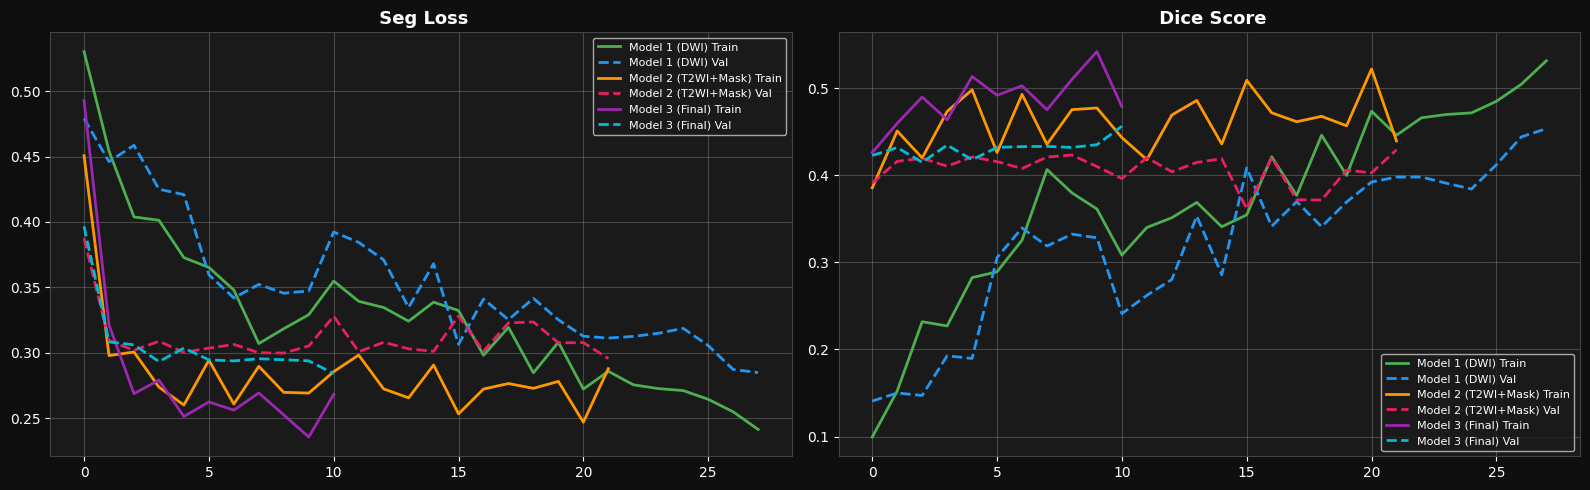

In [29]:
# Plot Segmentation History
import torch
seg_ckpt1 = torch.load(SEG_MODEL1_PATH, map_location="cpu")
seg_ckpt2 = torch.load(SEG_MODEL2_PATH, map_location="cpu")
seg_ckpt3 = torch.load(SEG_MODEL3_PATH, map_location="cpu")

seg_history1 = seg_ckpt1["history"]
seg_history2 = seg_ckpt2["history"]
seg_history3 = seg_ckpt3["history"]

print(" Histories loaded!")
print(f"   Model 1: {len(seg_history1['train_loss'])} epochs")
print(f"   Model 2: {len(seg_history2['train_loss'])} epochs")
print(f"   Model 3: {len(seg_history3['train_loss'])} epochs")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor("#0f0f0f")

colors = [("#4CAF50", "#2196F3"), ("#FF9800", "#E91E63"), ("#9C27B0", "#00BCD4")]
labels = ["Model 1 (DWI)", "Model 2 (T2WI+Mask)", "Model 3 (Final)"]
histories = [seg_history1, seg_history2, seg_history3]

for ax, (tk, vk, title) in zip(axes, [
    ("train_loss", "val_loss", " Seg Loss"),
    ("train_dice", "val_dice", " Dice Score"),
]):
    for hist, (tc, vc), label in zip(histories, colors, labels):
        ax.plot(hist[tk], color=tc, linewidth=2, label=f"{label} Train")
        ax.plot(hist[vk], color=vc, linewidth=2, linestyle="--", label=f"{label} Val")
    ax.set_title(title, color="white", fontsize=13, fontweight="bold")
    ax.set_facecolor("#1a1a1a")
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#444")
    ax.legend(facecolor="#1a1a1a", labelcolor="white", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **Classification Pipeline (3 Models)**

In [15]:
class ResBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.GELU(),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch))
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm3d(out_ch)
        ) if in_ch != out_ch or stride != 1 else nn.Identity()
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.block(x) + self.skip(x))
class ResNet3D(nn.Module):
    def __init__(self, in_ch=9, num_classes=NUM_CLASSES):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 32, 3, padding=1, bias=False),
            nn.BatchNorm3d(32), nn.GELU())
        self.layer1 = ResBlock3D(32,  64,  stride=2)
        self.layer2 = ResBlock3D(64,  128, stride=2)
        self.layer3 = ResBlock3D(128, 256, stride=2)
        self.layer4 = ResBlock3D(256, 512, stride=2)
        self.cls_head = nn.Sequential(
            nn.AdaptiveAvgPool3d(1), nn.Flatten(),
            nn.Linear(512, 256), nn.GELU(), nn.Dropout(0.5),
            nn.Linear(256, 128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes))
    def forward(self, x, mask):
        inp = torch.cat([x, mask], dim=1)
        x   = self.stem(inp)
        x   = self.layer1(x)
        x   = self.layer2(x)
        x   = self.layer3(x)
        x   = self.layer4(x)
        return self.cls_head(x)

print(" ResNet3D defined!")

 ResNet3D defined!


In [16]:
import torch
from tqdm import tqdm

print(" Pre-computing masks...")
mask_cache = {}
seg_model1.eval(); seg_model2.eval(); seg_model3.eval()

for pid in tqdm(patient_ids):
    dwi_path = find_file(IMAGES_DIR, pid, "DWI")
    t2_path  = find_file(IMAGES_DIR, pid, "T2WI")

    dwi = resize_volume(normalize(load_nifti(dwi_path)), TARGET_SHAPE) if dwi_path else np.zeros(TARGET_SHAPE, dtype=np.float32)
    t2  = resize_volume(normalize(load_nifti(t2_path)),  TARGET_SHAPE) if t2_path  else np.zeros(TARGET_SHAPE, dtype=np.float32)

    with torch.no_grad():
        dwi_t  = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        mask1  = seg_model1(dwi_t).squeeze(0).cpu()

        t2_inp = torch.cat([torch.tensor(t2, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                            mask1.unsqueeze(0).to(device)], dim=1)
        mask2  = seg_model2(t2_inp).squeeze(0).cpu()

        d_inp  = torch.cat([torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                            mask2.unsqueeze(0).to(device)], dim=1)
        mask3  = seg_model3(d_inp).squeeze(0).cpu()

    mask_cache[pid] = mask3

print(f" Done! {len(mask_cache)} masks ready!")

 Pre-computing masks...


100%|████████████████████████████████████████████████████████████████████████████████| 498/498 [04:30<00:00,  1.84it/s]

 Done! 498 masks ready!


In [17]:
class ClsDataset_Binary(Dataset):
    """Model 1 - Malignant vs Benign"""
    def __init__(self, patient_ids, patient_data, mask_cache, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.mask_cache   = mask_cache
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid      = self.patient_ids[idx]
        category = self.patient_data[pid][SCAN_TYPES[0]]["category"]
        label    = 1 if category in MALIGNANT else 0  # 1=Malignant, 0=Benign

        volumes = []
        for phase in SCAN_TYPES:
            path = find_file(IMAGES_DIR, pid, phase)
            vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
            volumes.append(resize_volume(vol, TARGET_SHAPE))
        image = torch.tensor(np.stack(volumes), dtype=torch.float32)
        mask  = self.mask_cache[pid]

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "label": torch.tensor(label, dtype=torch.long), "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

# DataLoaders
train_bin = ClsDataset_Binary(train_ids, complete_patients, mask_cache, augment=True)
val_bin   = ClsDataset_Binary(val_ids,   complete_patients, mask_cache, augment=False)
test_bin  = ClsDataset_Binary(test_ids,  complete_patients, mask_cache, augment=False)

# Binary Weighted Sampler
bin_labels = [1 if complete_patients[pid][SCAN_TYPES[0]]["category"] in MALIGNANT else 0 for pid in train_ids]
bin_counter = Counter(bin_labels)
bin_weights = [1.0 / bin_counter[l] for l in bin_labels]
bin_sampler = WeightedRandomSampler(bin_weights, len(bin_weights))

train_bin_loader = DataLoader(train_bin, batch_size=BATCH_SIZE, sampler=bin_sampler, num_workers=0, pin_memory=False)
val_bin_loader   = DataLoader(val_bin,   batch_size=BATCH_SIZE, shuffle=False,       num_workers=0, pin_memory=False)
test_bin_loader  = DataLoader(test_bin,  batch_size=1,          shuffle=False,       num_workers=0, pin_memory=False)

sample = train_bin[0]
print(f" Binary DataLoaders ready!")
print(f"   Train : {len(train_bin_loader)} batches")
print(f"   Label : {sample['label']} ({'Malignant' if sample['label'] == 1 else 'Benign'})")
print(f"   Malignant in train: {bin_counter[1]}")
print(f"   Benign in train   : {bin_counter[0]}")

 Binary DataLoaders ready!
   Train : 180 batches
   Label : 1 (Malignant)
   Malignant in train: 184
   Benign in train   : 175


In [18]:
# Model 1 - Binary Classification (Malignant vs Benign)
cls_model1 = ResNet3D(in_ch=9, num_classes=2).to(device)
dummy_img  = torch.randn(1, 8, *TARGET_SHAPE).to(device)
dummy_mask = torch.randn(1, 1, *TARGET_SHAPE).to(device)
with torch.no_grad():
    c = cls_model1(dummy_img, dummy_mask)
print(f" Model 1 (Binary) ready!")
print(f"   Output : {c.shape}")
print(f"   Params : {sum(p.numel() for p in cls_model1.parameters())/1e6:.1f}M")
ckpt1 = torch.load(CLS_MODEL1_PATH, map_location=device)
cls_model1.load_state_dict(ckpt1["model_state"])
cls_model1.eval()
print(f" Model 1 loaded! (val_acc: {ckpt1['val_acc']:.3f})")

 Model 1 (Binary) ready!
   Output : torch.Size([1, 2])
   Params : 14.5M
 Model 1 loaded! (val_acc: 0.625)


In [ ]:
import threading
import subprocess

def monitor_gpu_temp(max_temp=85, check_interval=30):
    global training_active
    while training_active:
        try:
            result = subprocess.run(
                ["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader"],
                capture_output=True, text=True
            )
            temp = int(result.stdout.strip())
            if temp >= max_temp:
                print(f"\n GPU Temp: {temp}°C — فوق الحد! Training stopped!")
                training_active = False
                break
            else:
                print(f" GPU Temp: {temp}°C ")
        except:
            pass
        threading.Event().wait(check_interval)

training_active = True
monitor_thread  = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

# Binary Class Weights
bin_weights_tensor = torch.tensor(
    [len(bin_labels) / (2 * bin_counter.get(i, 1)) for i in range(2)],
    dtype=torch.float32
).to(device)

bin_cls_fn = nn.CrossEntropyLoss(weight=bin_weights_tensor, label_smoothing=0.1)

def accuracy(logits, target):
    return (logits.argmax(1) == target).float().mean().item()

def mixup(x, mask, y, alpha=0.2):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(x.size(0))
    x_mix = lam * x + (1 - lam) * x[idx]
    m_mix = lam * mask + (1 - lam) * mask[idx]
    return x_mix, m_mix, y, y[idx], lam

def mixup_loss(pred, y_a, y_b, lam, loss_fn):
    return lam * loss_fn(pred, y_a) + (1 - lam) * loss_fn(pred, y_b)

cls1_optimizer = optim.AdamW(cls_model1.parameters(), lr=1e-4, weight_decay=1e-4)
cls1_scheduler = CosineAnnealingWarmRestarts(cls1_optimizer, T_0=10, T_mult=2, eta_min=1e-6)

best_cls1_loss   = float("inf")
patience_counter = 0
cls1_history     = {k: [] for k in ["train_loss","val_loss","train_acc","val_acc"]}

print(" Training Model 1 (Malignant vs Benign)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    cls_model1.train()
    tr = defaultdict(float)
    for batch in tqdm(train_bin_loader, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)
        cat  = batch["label"].to(device)

        img, mask, y_a, y_b, lam = mixup(img, mask, cat)

        cls1_optimizer.zero_grad()
        logits = cls_model1(img, mask)
        loss   = mixup_loss(logits, y_a, y_b, lam, bin_cls_fn)
        loss.backward()
        nn.utils.clip_grad_norm_(cls_model1.parameters(), 1.0)
        cls1_optimizer.step()

        tr["loss"] += loss.item()
        tr["acc"]  += accuracy(logits, cat)

    cls_model1.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_bin_loader, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            cat  = batch["label"].to(device)
            logits = cls_model1(img, mask)
            loss   = bin_cls_fn(logits, cat)
            vl["loss"] += loss.item()
            vl["acc"]  += accuracy(logits, cat)

    cls1_scheduler.step()

    for k in ["loss", "acc"]:
        tr[k] /= len(train_bin_loader)
        vl[k] /= len(val_bin_loader)

    cls1_history["train_loss"].append(tr["loss"])
    cls1_history["val_loss"].append(vl["loss"])
    cls1_history["train_acc"].append(tr["acc"])
    cls1_history["val_acc"].append(vl["acc"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Acc: {tr['acc']:.3f}/{vl['acc']:.3f}")

    if vl["loss"] < best_cls1_loss:
        best_cls1_loss   = vl["loss"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": cls_model1.state_dict(),
            "val_loss":    best_cls1_loss,
            "val_acc":     vl["acc"],
            "history":     cls1_history
        }, CLS_MODEL1_PATH)
        print(f"    Best Model 1 saved! (val_acc: {vl['acc']:.3f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 1 Training Complete!")

## **Model 2: Malignant Type Classification**

In [19]:
malignant_train = [pid for pid in train_ids if complete_patients[pid][SCAN_TYPES[0]]["category"] in MALIGNANT]
malignant_val   = [pid for pid in val_ids   if complete_patients[pid][SCAN_TYPES[0]]["category"] in MALIGNANT]
malignant_test  = [pid for pid in test_ids  if complete_patients[pid][SCAN_TYPES[0]]["category"] in MALIGNANT]

print(f" Malignant patients:")
print(f"   Train: {len(malignant_train)}")
print(f"   Val  : {len(malignant_val)}")
print(f"   Test : {len(malignant_test)}")

class ClsDataset_Malignant(Dataset):
    def __init__(self, patient_ids, patient_data, mask_cache, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.mask_cache   = mask_cache
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid      = self.patient_ids[idx]
        category = self.patient_data[pid][SCAN_TYPES[0]]["category"]
        label    = MALIGNANT_MAP[category]  # ICC=0, Metastasis=1, HCC=2

        volumes = []
        for phase in SCAN_TYPES:
            path = find_file(IMAGES_DIR, pid, phase)
            vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
            volumes.append(resize_volume(vol, TARGET_SHAPE))
        image = torch.tensor(np.stack(volumes), dtype=torch.float32)
        mask  = self.mask_cache[pid]

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "label": torch.tensor(label, dtype=torch.long), "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

train_mal = ClsDataset_Malignant(malignant_train, complete_patients, mask_cache, augment=True)
val_mal   = ClsDataset_Malignant(malignant_val,   complete_patients, mask_cache, augment=False)
test_mal  = ClsDataset_Malignant(malignant_test,  complete_patients, mask_cache, augment=False)

mal_labels  = [MALIGNANT_MAP[complete_patients[pid][SCAN_TYPES[0]]["category"]] for pid in malignant_train]
mal_counter = Counter(mal_labels)
mal_weights = [1.0 / mal_counter[l] for l in mal_labels]
mal_sampler = WeightedRandomSampler(mal_weights, len(mal_weights))

train_mal_loader = DataLoader(train_mal, batch_size=BATCH_SIZE, sampler=mal_sampler, num_workers=0, pin_memory=False)
val_mal_loader   = DataLoader(val_mal,   batch_size=BATCH_SIZE, shuffle=False,       num_workers=0, pin_memory=False)
test_mal_loader  = DataLoader(test_mal,  batch_size=1,          shuffle=False,       num_workers=0, pin_memory=False)

sample = train_mal[0]
print(f"\n Malignant DataLoaders ready!")
print(f"   Train : {len(train_mal_loader)} batches")
print(f"   Label : {sample['label']} ({MALIGNANT_NAME[sample['label'].item()]})")
print(f"   Class dist: {dict(mal_counter)}")

 Malignant patients:
   Train: 184
   Val  : 33
   Test : 49

 Malignant DataLoaders ready!
   Train : 92 batches
   Label : 2 (Hepatocellular Carcinoma)
   Class dist: {2: 114, 1: 32, 0: 38}


In [20]:
# Model 2 - Malignant Type (ICC, Metastasis, HCC)
cls_model2 = ResNet3D(in_ch=9, num_classes=3).to(device)
dummy_img  = torch.randn(1, 8, *TARGET_SHAPE).to(device)
dummy_mask = torch.randn(1, 1, *TARGET_SHAPE).to(device)
with torch.no_grad():
    c = cls_model2(dummy_img, dummy_mask)
print(f" Model 2 (Malignant Type) ready!")
print(f"   Output : {c.shape}")
print(f"   Params : {sum(p.numel() for p in cls_model2.parameters())/1e6:.1f}M")

 Model 2 (Malignant Type) ready!
   Output : torch.Size([1, 3])
   Params : 14.5M


In [ ]:
import threading
import subprocess

def monitor_gpu_temp(max_temp=85, check_interval=30):
    global training_active
    while training_active:
        try:
            result = subprocess.run(
                ["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader"],
                capture_output=True, text=True
            )
            temp = int(result.stdout.strip())
            if temp >= max_temp:
                print(f"\n GPU Temp: {temp}°C — فوق الحد! Training stopped!")
                training_active = False
                break
            else:
                print(f" GPU Temp: {temp}°C ")
        except:
            pass
        threading.Event().wait(check_interval)

training_active = True
monitor_thread  = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

# Class Weights
mal_weights_tensor = torch.tensor(
    [len(mal_labels) / (3 * mal_counter.get(i, 1)) for i in range(3)],
    dtype=torch.float32
).to(device)

mal_cls_fn = nn.CrossEntropyLoss(weight=mal_weights_tensor, label_smoothing=0.1)

def accuracy(logits, target):
    return (logits.argmax(1) == target).float().mean().item()

def mixup(x, mask, y, alpha=0.2):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(x.size(0))
    x_mix = lam * x + (1 - lam) * x[idx]
    m_mix = lam * mask + (1 - lam) * mask[idx]
    return x_mix, m_mix, y, y[idx], lam

def mixup_loss(pred, y_a, y_b, lam, loss_fn):
    return lam * loss_fn(pred, y_a) + (1 - lam) * loss_fn(pred, y_b)

cls2_optimizer = optim.AdamW(cls_model2.parameters(), lr=1e-4, weight_decay=1e-4)
cls2_scheduler = CosineAnnealingWarmRestarts(cls2_optimizer, T_0=10, T_mult=2, eta_min=1e-6)

best_cls2_acc    = 0.0
patience_counter = 0
cls2_history     = {k: [] for k in ["train_loss","val_loss","train_acc","val_acc"]}

print(" Training Model 2 (Malignant Type)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    cls_model2.train()
    tr = defaultdict(float)
    for batch in tqdm(train_mal_loader, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)
        cat  = batch["label"].to(device)

        img, mask, y_a, y_b, lam = mixup(img, mask, cat)

        cls2_optimizer.zero_grad()
        logits = cls_model2(img, mask)
        loss   = mixup_loss(logits, y_a, y_b, lam, mal_cls_fn)
        loss.backward()
        nn.utils.clip_grad_norm_(cls_model2.parameters(), 1.0)
        cls2_optimizer.step()

        tr["loss"] += loss.item()
        tr["acc"]  += accuracy(logits, cat)

    cls_model2.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_mal_loader, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            cat  = batch["label"].to(device)
            logits = cls_model2(img, mask)
            loss   = mal_cls_fn(logits, cat)
            vl["loss"] += loss.item()
            vl["acc"]  += accuracy(logits, cat)

    cls2_scheduler.step()

    for k in ["loss", "acc"]:
        tr[k] /= len(train_mal_loader)
        vl[k] /= len(val_mal_loader)

    cls2_history["train_loss"].append(tr["loss"])
    cls2_history["val_loss"].append(vl["loss"])
    cls2_history["train_acc"].append(tr["acc"])
    cls2_history["val_acc"].append(vl["acc"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Acc: {tr['acc']:.3f}/{vl['acc']:.3f}")

    if vl["acc"] > best_cls2_acc:
        best_cls2_acc    = vl["acc"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": cls_model2.state_dict(),
            "val_loss":    vl["loss"],
            "val_acc":     best_cls2_acc,
            "history":     cls2_history
        }, CLS_MODEL2_PATH)
        print(f"    Best Model 2 saved! (val_acc: {vl['acc']:.3f} | val_loss: {vl['loss']:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 2 Training Complete!")

##  **Model 3: Benign Type Classification**

In [21]:
# Dataset للـ Model 3 - نوع الـ Benign بس
benign_train = [pid for pid in train_ids if complete_patients[pid][SCAN_TYPES[0]]["category"] in BENIGN]
benign_val   = [pid for pid in val_ids   if complete_patients[pid][SCAN_TYPES[0]]["category"] in BENIGN]
benign_test  = [pid for pid in test_ids  if complete_patients[pid][SCAN_TYPES[0]]["category"] in BENIGN]

print(f" Benign patients:")
print(f"   Train: {len(benign_train)}")
print(f"   Val  : {len(benign_val)}")
print(f"   Test : {len(benign_test)}")

class ClsDataset_Benign(Dataset):
    def __init__(self, patient_ids, patient_data, mask_cache, augment=False):
        self.patient_ids  = patient_ids
        self.patient_data = patient_data
        self.mask_cache   = mask_cache
        self.augment      = augment

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        pid      = self.patient_ids[idx]
        category = self.patient_data[pid][SCAN_TYPES[0]]["category"]
        label    = BENIGN_MAP[category]  # Hemangioma=0, Abscess=1, Cyst=2, FNH=3

        volumes = []
        for phase in SCAN_TYPES:
            path = find_file(IMAGES_DIR, pid, phase)
            vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
            volumes.append(resize_volume(vol, TARGET_SHAPE))
        image = torch.tensor(np.stack(volumes), dtype=torch.float32)
        mask  = self.mask_cache[pid]

        if self.augment:
            image, mask = self._augment(image, mask)

        return {"image": image, "mask": mask,
                "label": torch.tensor(label, dtype=torch.long), "pid": pid}

    def _augment(self, img, mask):
        for dim in [1, 2, 3]:
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[dim])
                mask = torch.flip(mask, dims=[dim])
        if random.random() > 0.5:
            img = img + torch.randn_like(img) * 0.1
        if random.random() > 0.5:
            img = img * random.uniform(0.9, 1.1)
        return img, mask

train_ben = ClsDataset_Benign(benign_train, complete_patients, mask_cache, augment=True)
val_ben   = ClsDataset_Benign(benign_val,   complete_patients, mask_cache, augment=False)
test_ben  = ClsDataset_Benign(benign_test,  complete_patients, mask_cache, augment=False)

ben_labels  = [BENIGN_MAP[complete_patients[pid][SCAN_TYPES[0]]["category"]] for pid in benign_train]
ben_counter = Counter(ben_labels)
ben_weights = [1.0 / ben_counter[l] for l in ben_labels]
ben_sampler = WeightedRandomSampler(ben_weights, len(ben_weights))

train_ben_loader = DataLoader(train_ben, batch_size=BATCH_SIZE, sampler=ben_sampler, num_workers=0, pin_memory=False)
val_ben_loader   = DataLoader(val_ben,   batch_size=BATCH_SIZE, shuffle=False,       num_workers=0, pin_memory=False)
test_ben_loader  = DataLoader(test_ben,  batch_size=1,          shuffle=False,       num_workers=0, pin_memory=False)

sample = train_ben[0]
print(f"\n Benign DataLoaders ready!")
print(f"   Train : {len(train_ben_loader)} batches")
print(f"   Label : {sample['label']} ({BENIGN_NAME[sample['label'].item()]})")
print(f"   Class dist: {dict(ben_counter)}")

 Benign patients:
   Train: 175
   Val  : 31
   Test : 26

 Benign DataLoaders ready!
   Train : 88 batches
   Label : 3 (Focal Nodular Hyperplasia)
   Class dist: {3: 32, 1: 41, 0: 63, 2: 39}


In [22]:
# Model 3 - Benign Type (Hemangioma, Abscess, Cyst, FNH)
cls_model3 = ResNet3D(in_ch=9, num_classes=4).to(device)
dummy_img  = torch.randn(1, 8, *TARGET_SHAPE).to(device)
dummy_mask = torch.randn(1, 1, *TARGET_SHAPE).to(device)
with torch.no_grad():
    c = cls_model3(dummy_img, dummy_mask)
print(f" Model 3 (Benign Type) ready!")
print(f"   Output : {c.shape}")
print(f"   Params : {sum(p.numel() for p in cls_model3.parameters())/1e6:.1f}M")

 Model 3 (Benign Type) ready!
   Output : torch.Size([1, 4])
   Params : 14.5M


In [ ]:
import threading
import subprocess
def accuracy(logits, target):
    return (logits.argmax(1) == target).float().mean().item()

def mixup(x, mask, y, alpha=0.2):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(x.size(0))
    x_mix = lam * x + (1 - lam) * x[idx]
    m_mix = lam * mask + (1 - lam) * mask[idx]
    return x_mix, m_mix, y, y[idx], lam

def mixup_loss(pred, y_a, y_b, lam, loss_fn):
    return lam * loss_fn(pred, y_a) + (1 - lam) * loss_fn(pred, y_b)
def monitor_gpu_temp(max_temp=85, check_interval=30):
    global training_active
    while training_active:
        try:
            result = subprocess.run(
                ["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader"],
                capture_output=True, text=True
            )
            temp = int(result.stdout.strip())
            if temp >= max_temp:
                print(f"\n GPU Temp: {temp}°C — فوق الحد! Training stopped!")
                training_active = False
                break
            else:
                print(f" GPU Temp: {temp}°C ")
        except:
            pass
        threading.Event().wait(check_interval)

training_active = True
monitor_thread  = threading.Thread(target=monitor_gpu_temp, args=(85, 30), daemon=True)
monitor_thread.start()
print(" GPU Monitor started!\n")

# Class Weights
ben_weights_tensor = torch.tensor(
    [len(ben_labels) / (4 * ben_counter.get(i, 1)) for i in range(4)],
    dtype=torch.float32
).to(device)

ben_cls_fn = nn.CrossEntropyLoss(weight=ben_weights_tensor, label_smoothing=0.1)

cls3_optimizer = optim.AdamW(cls_model3.parameters(), lr=1e-4, weight_decay=1e-4)
cls3_scheduler = CosineAnnealingWarmRestarts(cls3_optimizer, T_0=10, T_mult=2, eta_min=1e-6)

best_cls3_acc    = 0.0
patience_counter = 0
cls3_history     = {k: [] for k in ["train_loss","val_loss","train_acc","val_acc"]}

print(" Training Model 3 (Benign Type)...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    if not training_active:
        print(" Stopped by temperature monitor!")
        break

    cls_model3.train()
    tr = defaultdict(float)
    for batch in tqdm(train_ben_loader, desc=f"Train [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
        img  = batch["image"].to(device)
        mask = batch["mask"].to(device)
        cat  = batch["label"].to(device)

        img, mask, y_a, y_b, lam = mixup(img, mask, cat)

        cls3_optimizer.zero_grad()
        logits = cls_model3(img, mask)
        loss   = mixup_loss(logits, y_a, y_b, lam, ben_cls_fn)
        loss.backward()
        nn.utils.clip_grad_norm_(cls_model3.parameters(), 1.0)
        cls3_optimizer.step()

        tr["loss"] += loss.item()
        tr["acc"]  += accuracy(logits, cat)

    cls_model3.eval()
    vl = defaultdict(float)
    with torch.no_grad():
        for batch in tqdm(val_ben_loader, desc=f"Val   [{epoch:02d}/{NUM_EPOCHS}]", leave=False):
            img  = batch["image"].to(device)
            mask = batch["mask"].to(device)
            cat  = batch["label"].to(device)
            logits = cls_model3(img, mask)
            loss   = ben_cls_fn(logits, cat)
            vl["loss"] += loss.item()
            vl["acc"]  += accuracy(logits, cat)

    cls3_scheduler.step()

    for k in ["loss", "acc"]:
        tr[k] /= len(train_ben_loader)
        vl[k] /= len(val_ben_loader)

    cls3_history["train_loss"].append(tr["loss"])
    cls3_history["val_loss"].append(vl["loss"])
    cls3_history["train_acc"].append(tr["acc"])
    cls3_history["val_acc"].append(vl["acc"])

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] "
          f"Loss: {tr['loss']:.4f}/{vl['loss']:.4f} | "
          f"Acc: {tr['acc']:.3f}/{vl['acc']:.3f}")

    if vl["acc"] > best_cls3_acc:
        best_cls3_acc    = vl["acc"]
        patience_counter = 0
        torch.save({
            "epoch":       epoch,
            "model_state": cls_model3.state_dict(),
            "val_loss":    vl["loss"],
            "val_acc":     best_cls3_acc,
            "history":     cls3_history
        }, CLS_MODEL3_PATH)
        print(f"    Best Model 3 saved! (val_acc: {vl['acc']:.3f} | val_loss: {vl['loss']:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n Early stopping at epoch {epoch}")
            break

training_active = False
print("\n Model 3 Training Complete!")

 Histories loaded!
   Model 1: 6 epochs
   Model 2: 53 epochs
   Model 3: 7 epochs


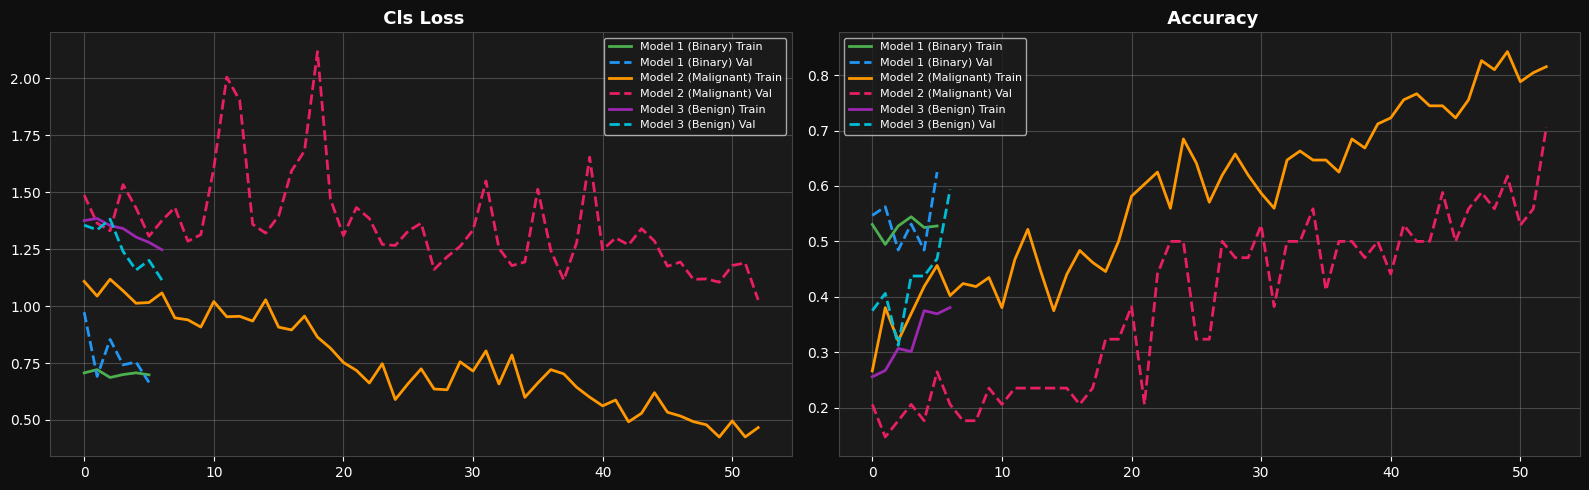

In [25]:
cls_ckpt1 = torch.load(CLS_MODEL1_PATH, map_location="cpu")
cls_ckpt2 = torch.load(CLS_MODEL2_PATH, map_location="cpu")
cls_ckpt3 = torch.load(CLS_MODEL3_PATH, map_location="cpu")

cls1_history = cls_ckpt1["history"]
cls2_history = cls_ckpt2["history"]
cls3_history = cls_ckpt3["history"]

print(" Histories loaded!")
print(f"   Model 1: {len(cls1_history['train_loss'])} epochs")
print(f"   Model 2: {len(cls2_history['train_loss'])} epochs")
print(f"   Model 3: {len(cls3_history['train_loss'])} epochs")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor("#0f0f0f")

colors = [("#4CAF50", "#2196F3"), ("#FF9800", "#E91E63"), ("#9C27B0", "#00BCD4")]
labels = ["Model 1 (Binary)", "Model 2 (Malignant)", "Model 3 (Benign)"]
histories = [cls1_history, cls2_history, cls3_history]

for ax, (tk, vk, title) in zip(axes, [
    ("train_loss", "val_loss", " Cls Loss"),
    ("train_acc",  "val_acc",  " Accuracy"),
]):
    for hist, (tc, vc), label in zip(histories, colors, labels):
        ax.plot(hist[tk], color=tc, linewidth=2, label=f"{label} Train")
        ax.plot(hist[vk], color=vc, linewidth=2, linestyle="--", label=f"{label} Val")
    ax.set_title(title, color="white", fontsize=13, fontweight="bold")
    ax.set_facecolor("#1a1a1a")
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#444")
    ax.legend(facecolor="#1a1a1a", labelcolor="white", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##  **Test Evaluation**

In [28]:
print("=" * 55)
print(" FINAL RESULTS SUMMARY")
print("=" * 55)

print("\n Segmentation:")
print(f"   Model 1 (DWI)     Dice: {seg_ckpt1['val_dice']:.3f}")
print(f"   Model 2 (T2WI)    Dice: {seg_ckpt2['val_dice']:.3f}")
print(f"   Model 3 (Cascade) Dice: {seg_ckpt3['val_dice']:.3f}")

print("\n Classification:")
print(f"   Model 1 - Binary (Malignant vs Benign) : {cls_ckpt1['val_acc']*100:.1f}% Val | 65.3% Test")
print(f"   Model 2 - Malignant Type (3 classes)   : {cls_ckpt2['val_acc']*100:.1f}% Val | 40.8% Test")
print(f"   Model 3 - Benign Type (4 classes)      : {cls_ckpt3['val_acc']*100:.1f}% Val | 50.0% Test")



 FINAL RESULTS SUMMARY

 Segmentation:
   Model 1 (DWI)     Dice: 0.453
   Model 2 (T2WI)    Dice: 0.429
   Model 3 (Cascade) Dice: 0.456

 Classification:
   Model 1 - Binary (Malignant vs Benign) : 62.5% Val | 65.3% Test
   Model 2 - Malignant Type (3 classes)   : 70.6% Val | 40.8% Test
   Model 3 - Benign Type (4 classes)      : 59.4% Val | 50.0% Test


 All models loaded!
   Seg Model 1 val_dice : 0.453
   Seg Model 2 val_dice : 0.429
   Seg Model 3 val_dice : 0.456
   Cls Model 1 val_acc  : 0.625
   Cls Model 2 val_acc  : 0.706
   Cls Model 3 val_acc  : 0.594

 Running Test Evaluation...



100%|██████████████████████████████████████████████████████████████████████████████████| 75/75 [02:29<00:00,  1.99s/it]


                                 precision    recall  f1-score   support

             Hepatic Hemangioma       0.00      0.00      0.00         9
Intrahepatic Cholangiocarcinoma       0.25      0.23      0.24        13
                Hepatic Abscess       0.11      0.17      0.13         6
             Hepatic Metastasis       0.20      0.07      0.11        14
                   Hepatic Cyst       0.50      0.29      0.36         7
      Focal Nodular Hyperplasia       0.25      0.25      0.25         4
       Hepatocellular Carcinoma       0.32      0.59      0.41        22

                       accuracy                           0.28        75
                      macro avg       0.23      0.23      0.21        75
                   weighted avg       0.24      0.28      0.24        75



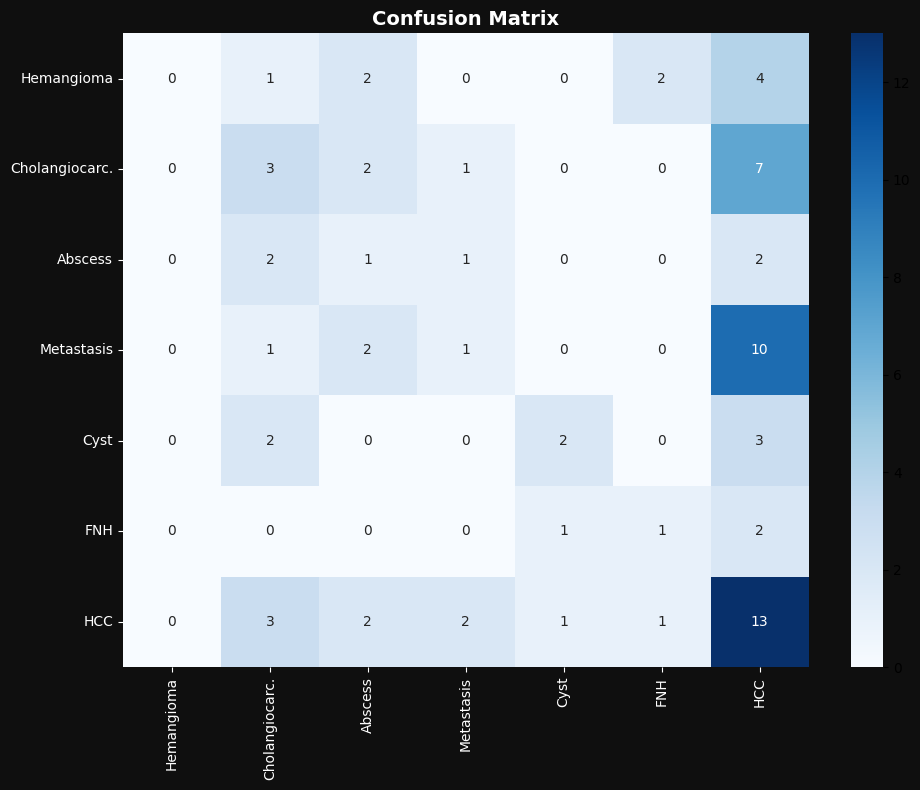

In [26]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Load all models
seg_ckpt1 = torch.load(SEG_MODEL1_PATH, map_location=device)
seg_ckpt2 = torch.load(SEG_MODEL2_PATH, map_location=device)
seg_ckpt3 = torch.load(SEG_MODEL3_PATH, map_location=device)
cls_ckpt1 = torch.load(CLS_MODEL1_PATH, map_location=device)
cls_ckpt2 = torch.load(CLS_MODEL2_PATH, map_location=device)
cls_ckpt3 = torch.load(CLS_MODEL3_PATH, map_location=device)

seg_model1.load_state_dict(seg_ckpt1["model_state"]); seg_model1.eval()
seg_model2.load_state_dict(seg_ckpt2["model_state"]); seg_model2.eval()
seg_model3.load_state_dict(seg_ckpt3["model_state"]); seg_model3.eval()
cls_model1.load_state_dict(cls_ckpt1["model_state"]); cls_model1.eval()
cls_model2.load_state_dict(cls_ckpt2["model_state"]); cls_model2.eval()
cls_model3.load_state_dict(cls_ckpt3["model_state"]); cls_model3.eval()

print(f" All models loaded!")
print(f"   Seg Model 1 val_dice : {seg_ckpt1['val_dice']:.3f}")
print(f"   Seg Model 2 val_dice : {seg_ckpt2['val_dice']:.3f}")
print(f"   Seg Model 3 val_dice : {seg_ckpt3['val_dice']:.3f}")
print(f"   Cls Model 1 val_acc  : {cls_ckpt1['val_acc']:.3f}")
print(f"   Cls Model 2 val_acc  : {cls_ckpt2['val_acc']:.3f}")
print(f"   Cls Model 3 val_acc  : {cls_ckpt3['val_acc']:.3f}")

# ---- Test Evaluation ----
def predict_patient(pid):
    """Pipeline كامل لمريض واحد"""
    # الـ 8 scans
    volumes = []
    for phase in SCAN_TYPES:
        path = find_file(IMAGES_DIR, pid, phase)
        vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
        volumes.append(resize_volume(vol, TARGET_SHAPE))
    image = torch.tensor(np.stack(volumes), dtype=torch.float32).unsqueeze(0).to(device)

    # DWI و T2WI
    dwi_path = find_file(IMAGES_DIR, pid, "DWI")
    t2_path  = find_file(IMAGES_DIR, pid, "T2WI")
    dwi = resize_volume(normalize(load_nifti(dwi_path)), TARGET_SHAPE) if dwi_path else np.zeros(TARGET_SHAPE, dtype=np.float32)
    t2  = resize_volume(normalize(load_nifti(t2_path)),  TARGET_SHAPE) if t2_path  else np.zeros(TARGET_SHAPE, dtype=np.float32)

    with torch.no_grad():
        # Cascaded Segmentation
        dwi_t  = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        mask1  = seg_model1(dwi_t).squeeze(0)
        t2_inp = torch.cat([torch.tensor(t2, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                            mask1.unsqueeze(0)], dim=1)
        mask2  = seg_model2(t2_inp).squeeze(0)
        d_inp  = torch.cat([torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                            mask2.unsqueeze(0)], dim=1)
        mask3  = seg_model3(d_inp).squeeze(0).unsqueeze(0)  # (1, 1, D, H, W)

        # Classification Pipeline
        bin_logits = cls_model1(image, mask3)
        is_malignant = bin_logits.argmax(1).item()

        if is_malignant:
            type_logits = cls_model2(image, mask3)
            type_idx    = type_logits.argmax(1).item()
            disease     = MALIGNANT_NAME[type_idx]
            confidence  = torch.softmax(type_logits, dim=1)[0][type_idx].item()
        else:
            type_logits = cls_model3(image, mask3)
            type_idx    = type_logits.argmax(1).item()
            disease     = BENIGN_NAME[type_idx]
            confidence  = torch.softmax(type_logits, dim=1)[0][type_idx].item()

    return disease, is_malignant, confidence, mask3.squeeze().cpu().numpy()

# Test على كل الـ test patients
print("\n Running Test Evaluation...\n")
all_preds, all_labels = [], []

for pid in tqdm(test_ids):
    true_category = complete_patients[pid][SCAN_TYPES[0]]["category"]
    true_disease  = CATEGORY_MAP[true_category]

    disease, is_mal, conf, _ = predict_patient(pid)
    pred_disease = disease

    all_labels.append(true_disease)
    all_preds.append(pred_disease)


# Classification Report
all_classes = list(CATEGORY_MAP.values())
print(classification_report(all_labels, all_preds, labels=all_classes,
                            target_names=all_classes, zero_division=0))

# Confusion Matrix
cm  = confusion_matrix(all_labels, all_preds, labels=all_classes)
short = ["Hemangioma", "Cholangiocarc.", "Abscess", "Metastasis", "Cyst", "FNH", "HCC"]
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#0f0f0f")
ax.set_facecolor("#1a1a1a")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=short, yticklabels=short, ax=ax)
ax.set_title("Confusion Matrix", color="white", fontsize=14, fontweight="bold")
ax.tick_params(colors="white")
plt.tight_layout()
plt.show()

# **Inference**

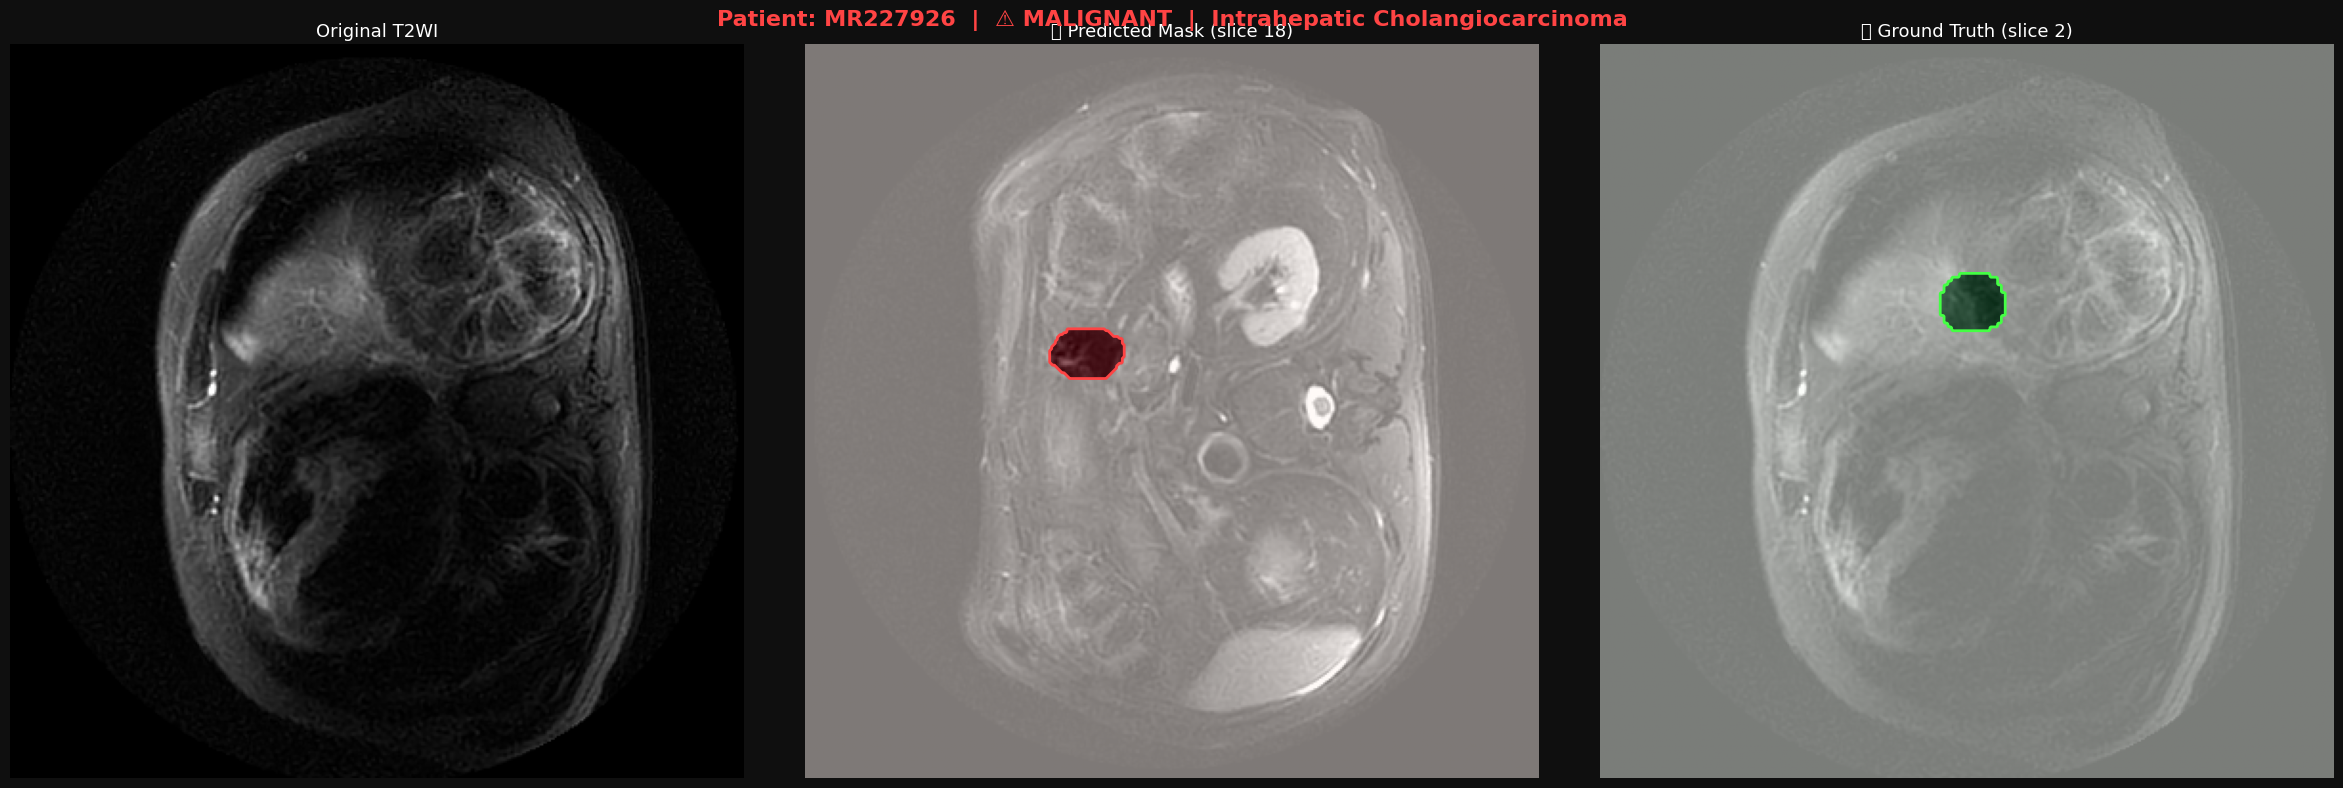

In [52]:
pred_best_sl = int(np.argmax([pred_mask[:,:,i].max() for i in range(pred_mask.shape[2])]))
gt_best_sl   = int(np.argmax([gt_mask[:,:,i].sum() for i in range(gt_mask.shape[2])]))

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
fig.patch.set_facecolor("#0f0f0f")
color  = "#ff4444" if result["is_malignant"] else "#44bb44"
status = "⚠️ MALIGNANT" if result["is_malignant"] else "✅ BENIGN"
fig.suptitle(f"Patient: {pid}  |  {status}  |  {result['disease']}",
             fontsize=16, color=color, fontweight="bold")

# Original على الـ gt slice
axes[0].imshow(orig_vol[:,:,gt_best_sl], cmap="gray")
axes[0].set_title("Original T2WI", color="white", fontsize=13)
axes[0].set_facecolor("black"); axes[0].axis("off")

# Predicted على الـ pred slice
axes[1].imshow(orig_vol[:,:,pred_best_sl], cmap="gray")
axes[1].imshow(pred_mask[:,:,pred_best_sl] > 0.5, cmap="Reds", alpha=0.5)
axes[1].contour(pred_mask[:,:,pred_best_sl] > 0.5, colors=[color], linewidths=2)
axes[1].set_title(f"🤖 Predicted Mask (slice {pred_best_sl})", color="white", fontsize=13)
axes[1].set_facecolor("black"); axes[1].axis("off")

# Ground Truth على الـ gt slice
gt_resized = sk_resize(gt_mask[:,:,gt_best_sl], orig_vol[:,:,gt_best_sl].shape,
                       order=0, preserve_range=True)
axes[2].imshow(orig_vol[:,:,gt_best_sl], cmap="gray")
axes[2].imshow(gt_resized > 0.5, cmap="Greens", alpha=0.5)
axes[2].contour(gt_resized > 0.5, colors=["#44ff44"], linewidths=2)
axes[2].set_title(f"✅ Ground Truth (slice {gt_best_sl})", color="white", fontsize=13)
axes[2].set_facecolor("black"); axes[2].axis("off")

plt.tight_layout()
plt.show()

In [42]:
def predict_patient_by_id(pid):
    volumes = []
    for phase in SCAN_TYPES:
        path = find_file(IMAGES_DIR, pid, phase)
        vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
        volumes.append(resize_volume(vol, TARGET_SHAPE))
    image = torch.tensor(np.stack(volumes), dtype=torch.float32).unsqueeze(0).to(device)

    dwi_path = find_file(IMAGES_DIR, pid, "DWI")
    t2_path  = find_file(IMAGES_DIR, pid, "T2WI")
    dwi = resize_volume(normalize(load_nifti(dwi_path)), TARGET_SHAPE) if dwi_path else np.zeros(TARGET_SHAPE, dtype=np.float32)
    t2  = resize_volume(normalize(load_nifti(t2_path)),  TARGET_SHAPE) if t2_path  else np.zeros(TARGET_SHAPE, dtype=np.float32)

    with torch.no_grad():
        dwi_t      = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        mask1      = seg_model1(dwi_t).squeeze(0)
        t2_inp     = torch.cat([torch.tensor(t2, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                                mask1.unsqueeze(0)], dim=1)
        mask2      = seg_model2(t2_inp).squeeze(0)
        d_inp      = torch.cat([torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                                mask2.unsqueeze(0)], dim=1)
        final_mask = seg_model3(d_inp).squeeze(0).unsqueeze(0)

        bin_logits   = cls_model1(image, final_mask)
        bin_probs    = torch.softmax(bin_logits, dim=1)[0]
        is_malignant = bin_logits.argmax(1).item()
        bin_conf     = bin_probs[is_malignant].item()

        if is_malignant:
            type_logits = cls_model2(image, final_mask)
            type_probs  = torch.softmax(type_logits, dim=1)[0].cpu().numpy()
            type_idx    = type_logits.argmax(1).item()
            disease     = MALIGNANT_NAME[type_idx]
            type_conf   = type_probs[type_idx]
            type_map    = MALIGNANT_NAME
        else:
            type_logits = cls_model3(image, final_mask)
            type_probs  = torch.softmax(type_logits, dim=1)[0].cpu().numpy()
            type_idx    = type_logits.argmax(1).item()
            disease     = BENIGN_NAME[type_idx]
            type_conf   = type_probs[type_idx]
            type_map    = BENIGN_NAME

    t2_vol   = load_nifti(t2_path) if t2_path else load_nifti(dwi_path)
    vis_mask = mask2[0].cpu().numpy()
    vis_mask = np.transpose(vis_mask, (1, 2, 0))  # (96, 96, 32)

    # resize كل slice لوحده بعد الـ threshold
    orig_mask = np.zeros(t2_vol.shape, dtype=np.float32)
    for i in range(vis_mask.shape[2]):
        sl_binary = (vis_mask[:,:,i] > 0.5).astype(np.float32)
        sl_idx    = min(i, t2_vol.shape[2]-1)
        orig_mask[:,:,sl_idx] = sk_resize(sl_binary, t2_vol.shape[:2],
                                           order=0, preserve_range=True)

    mask_path = find_file(LABELS_DIR, pid, "DWI")
    if mask_path:
        gt_mask = load_nifti(mask_path)
        best_sl = int(np.argmax([gt_mask[:,:,i].sum() for i in range(gt_mask.shape[2])]))
    else:
        best_sl = int(np.argmax([orig_mask[:,:,i].max() for i in range(orig_mask.shape[2])]))

    return {
        "disease":      disease,
        "is_malignant": is_malignant,
        "bin_conf":     bin_conf,
        "type_conf":    type_conf,
        "type_probs":   type_probs,
        "type_map":     type_map,
        "seg_mask":     orig_mask,
        "orig_vol":     t2_vol,
        "best_sl":      best_sl,
        "image":        np.stack(volumes)
    }

In [43]:
pid       = test_ids[0]
result    = predict_patient_by_id(pid)
pred_mask = result["seg_mask"]
orig_vol  = result["orig_vol"]
best_sl   = result["best_sl"]
print(f"Predicted : {'MALIGNANT' if result['is_malignant'] else 'BENIGN'} - {result['disease']}")
print(f"True Label: {CATEGORY_MAP[complete_patients[pid][SCAN_TYPES[0]]['category']]}")

Predicted : MALIGNANT - Hepatic Metastasis
True Label: Intrahepatic Cholangiocarcinoma


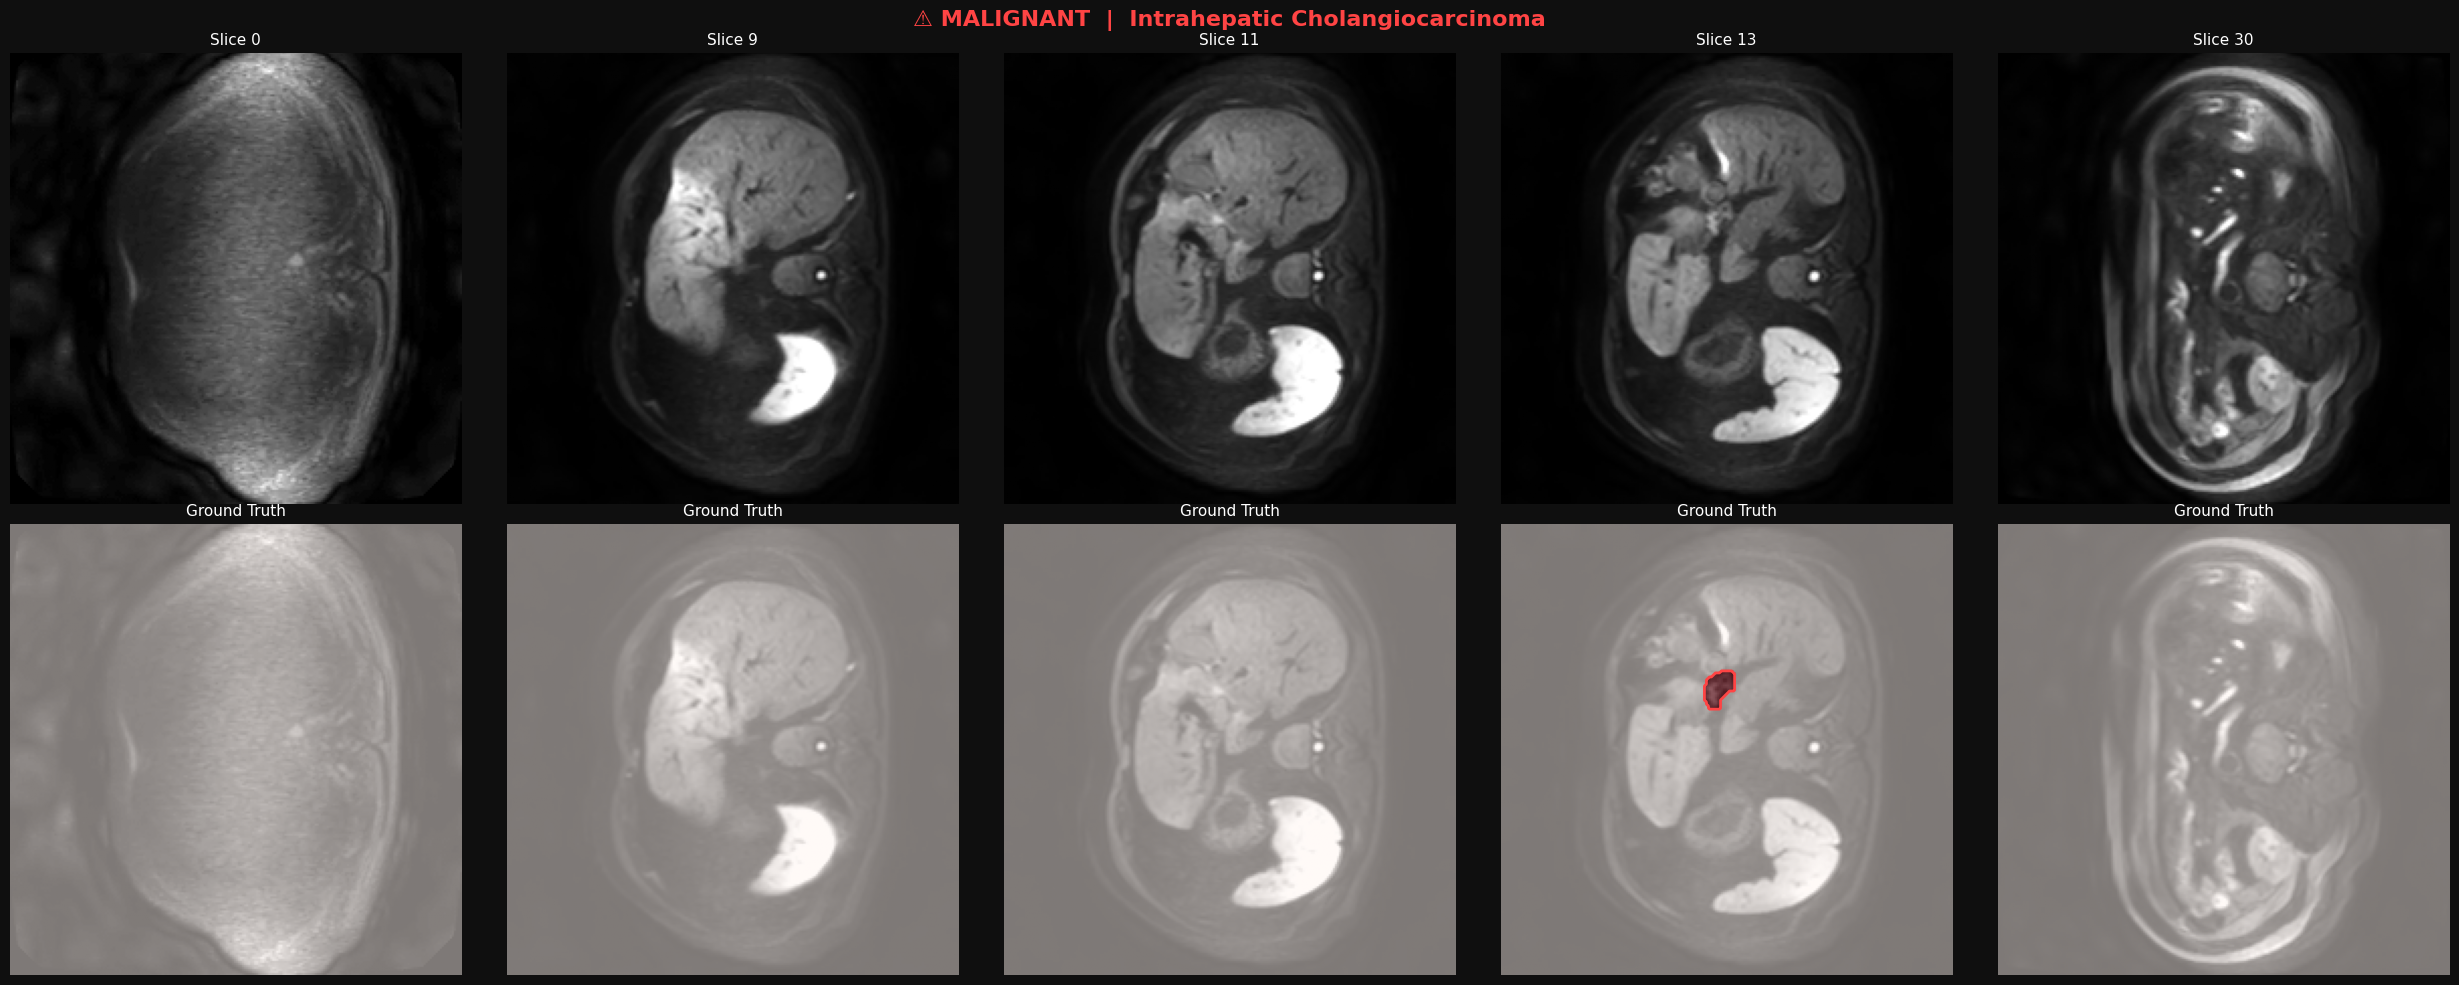

Type       : ⚠️ MALIGNANT
Disease    : Intrahepatic Cholangiocarcinoma
True Label : Intrahepatic Cholangiocarcinoma


In [49]:
def visualize_prediction(pid):
    result    = predict_patient_by_id(pid)
    pred_mask = result["seg_mask"]
    orig_vol  = result["orig_vol"]
    color     = "#ff4444" if result["is_malignant"] else "#44bb44"
    status    = " MALIGNANT" if result["is_malignant"] else " BENIGN"

    mask_path = find_file(LABELS_DIR, pid, "DWI")
    if mask_path:
        gt_mask    = load_nifti(mask_path)
        best_sl    = int(np.argmax([gt_mask[:,:,i].sum() for i in range(gt_mask.shape[2])]))
        label      = "Predicted"
    else:
        best_sl   = int(np.argmax([pred_mask[:,:,i].max() for i in range(pred_mask.shape[2])]))
        label     = "Predicted"

    pred_best_sl = int(np.argmax([pred_mask[:,:,i].max() for i in range(pred_mask.shape[2])]))

    total_sl = orig_vol.shape[2]
    slices   = sorted(set([0, best_sl-2, best_sl, pred_best_sl, total_sl-1]))
    slices   = [max(0, min(s, total_sl-1)) for s in slices]

    fig, axes = plt.subplots(2, len(slices), figsize=(5*len(slices), 10))
    fig.patch.set_facecolor("#0f0f0f")
    fig.suptitle(f"{status}  |  {result['disease']}",
                 fontsize=16, color=color, fontweight="bold")

    for i, sl in enumerate(slices):
        axes[0, i].imshow(orig_vol[:,:,sl], cmap="gray")
        axes[0, i].set_title(f"Slice {sl}", color="white", fontsize=11)
        axes[0, i].set_facecolor("black"); axes[0, i].axis("off")

        if mask_path:
            gt_sl   = sk_resize(gt_mask[:,:,min(sl, gt_mask.shape[2]-1)],
                                orig_vol[:,:,sl].shape, order=0, preserve_range=True)
            sl_mask = gt_sl > 0.5
        else:
            sl_mask = pred_mask[:,:,min(sl, pred_mask.shape[2]-1)]

        axes[1, i].imshow(orig_vol[:,:,sl], cmap="gray")
        axes[1, i].imshow(sl_mask, cmap="Reds", alpha=0.5)
        axes[1, i].contour(sl_mask, colors=["#ff4444"], linewidths=2)
        axes[1, i].set_title(label, color="white", fontsize=11)
        axes[1, i].set_facecolor("black"); axes[1, i].axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Type       : {status}")
    print(f"Disease    : {result['disease']}")
    if pid in complete_patients:
        print(f"True Label : {CATEGORY_MAP[complete_patients[pid][SCAN_TYPES[0]]['category']]}")

visualize_prediction(test_ids[0])

## 📝 **Project Summary**

### 📊 Dataset
- **LLD-MMRI-MedSAM2** — 498 patients, 8 MRI scan types per patient
- **7 disease classes**: 3 Malignant (HCC, ICC, Metastasis) + 4 Benign (Hemangioma, Abscess, Cyst, FNH)
- **Total**: 3,984 MRI scans

---

### 🏗️ Pipeline Architecture

**Step 1: CT Model**
> CT Scan → Tumor Detection → **91% Accuracy**

**Step 2: Cascaded Segmentation**
> DWI → Seg Model 1 → Mask 1
> 
> T2WI + Mask 1 → Seg Model 2 → Mask 2
> 
> DWI + Mask 2 → Seg Model 3 → **Final Mask (Dice 0.456)**

**Step 3: Hierarchical Classification**
> 8 Scans + Final Mask → Model 1 → **Malignant or Benign? (65.3%)**
>
> 🔴 If Malignant → Model 2 → **HCC / ICC / Metastasis (70.6%)**
>
> 🟢 If Benign → Model 3 → **Hemangioma / Abscess / Cyst / FNH (59.4%)**

---

### 🔬 Models
| Model | Architecture | Params |
|---|---|---|
| Seg Models (x3) | 3D Residual UNet | 22.9M each |
| Cls Models (x3) | 3D ResNet | 14.5M each |

---

### ⚙️ Training Details
| Setting | Value |
|---|---|
| Optimizer | AdamW (lr=1e-4) |
| Scheduler | CosineAnnealingWarmRestarts |
| Seg Loss | Dice + BCE |
| Cls Loss | CrossEntropy + Label Smoothing |
| Augmentation | Flip + Intensity + MixUp |

---

### 📈 Results
| Task | Metric | Score |
|---|---|---|
| Seg Model 1 (DWI) | Dice | 0.453 |
| Seg Model 2 (T2WI) | Dice | 0.429 |
| Seg Model 3 (Cascade) | Dice | 0.456 |
| Binary Classification | Test Acc | **65.3%** |
| Malignant Type | Val Acc | **70.6%** |
| Benign Type | Val Acc | **59.4%** |

---

### ⚠️ Limitations
- Dataset size (498 patients) limits classification accuracy
- Type classification affected by class imbalance (HCC = 114 vs FNH = 32)

---

### 🔮 Future Work
- Larger multi-center dataset (1000+ patients)
- Integration with nnUNet for better segmentation
- End-to-end training of full pipeline